# So sánh 11 mô hình base, Stacking Ridge và CatBoost

Huấn luyện lần lượt đúng danh sách: **Random Forest → Extra Trees → XGBoost → Decision Tree → Bayesian Ridge → Gradient Boosting → Hist Gradient Boosting → SVR → Ridge → Elastic Net → Dummy → Stacking (Ridge, top 4 base) → CatBoost**. CatBoost là mô hình đối chứng riêng, không nằm trong danh sách 11 base để chọn top 4.

Các mô hình dùng cùng 579 bản ghi, cùng nhãn năng suất tấn/ha, cùng danh sách đặc trưng và cùng mốc chia năm. Dùng cấu hình base cố định; không tìm siêu tham số hoặc chọn lại thành phần Stacking sau khi xem Test. Dummy là mốc dự đoán trung bình và cũng được xếp hạng trong 11 base.

- Train **2000–2015**, 399 dòng: fit từng base.
- Validation/phát triển **2016–2018**, 76 dòng: chọn 4 base theo MAE → RMSE → tên. Tạo thêm dự đoán ngoài mẫu tiến theo năm để học Ridge của Stacking.
- Test **2019–2022**, 104 dòng: so sánh 13 mô hình trên cùng các dòng. Không đưa Test vào fit hoặc dừng sớm.

**Không báo điểm Validation của Stacking:** nhãn 2016–2018 đã dùng chọn thành phần và học meta learner. Điểm fit của Ridge trên các dự đoán ngoài mẫu cũng không phải điểm kiểm định Stacking. Kết luận hiệu quả Stacking dựa trên Test chung, đối chiếu với từng base và CatBoost.

Cài `python -m pip install -r notebook/requirements-training.txt` từ gốc dự án, chọn đúng kernel rồi Restart Kernel → Run All. `xgboost-cpu` cung cấp module `xgboost`, không cần CUDA.

**Lưu mô hình:** sau bảng so sánh, lấy top 3 riêng cho MAE thấp nhất, RMSE thấp nhất và R² cao nhất trên Test 2019–2022. Chọn mô hình xuất hiện nhiều nhất trong ba top 3; nếu bằng số lần, ưu tiên MAE thấp hơn, rồi RMSE thấp hơn, R² cao hơn và tên để kết quả xác định. Chỉ lưu mô hình thắng cuộc và tiền xử lý cần cho suy luận. Nếu Stacking thắng, file duy nhất chứa 4 base thành phần và Ridge cần thiết. Vì Test được dùng chọn mô hình để lưu, điểm của mô hình thắng không phải đánh giá độc lập sau lựa chọn; muốn kiểm chứng cần dữ liệu mới.

## Phạm vi và giới hạn dữ liệu

Đây là **ước lượng hồi cứu sau khi có đủ dữ liệu cửa sổ vụ**, trên các tỉnh đã xuất hiện trong lịch sử; chưa đo khả năng dự báo trước thu hoạch hoặc chuyển sang tỉnh mới.

- GEE hiện dùng VCI chuẩn **2000–2015**. Vì vậy các fold dùng cho meta learner bắt đầu từ **2016**, khi toàn bộ mốc chuẩn đã thuộc quá khứ. Không tạo fold dự đoán 2008–2015 với chuẩn VCI chứa dữ liệu sau thời điểm fold.
- Mặt nạ lúa **2020** được áp dụng cho lịch sử. Đây là giới hạn thông tin đầu vào mà chia tập theo năm không loại bỏ được. Muốn kiểm định dự báo vận hành nghiêm ngặt phải xuất lại đặc trưng bằng mặt nạ có sẵn tại từng thời điểm.
- Cửa sổ vụ là đại diện: đông xuân tháng 11–4; hè thu–thu đông tháng 4–11. Năm 2000 thiếu vệ tinh đầu cửa sổ. Giữ các biến chất lượng để mô tả độ phủ.
- Test 2019–2022 đã xuất hiện trong phiên bản CatBoost trước. So sánh lần này là thí nghiệm tiếp theo trên cùng giai đoạn, không phải một holdout hoàn toàn mới. Không dùng kết quả lần này để tiếp tục chỉnh cấu hình trong notebook. Kết quả được dùng xếp hạng và chọn mô hình để lưu, nên không coi điểm mô hình thắng là đánh giá Test độc lập sau lựa chọn.
- Một giai đoạn Test, chỉ 4 năm và các dòng tương quan theo tỉnh/năm, chưa đủ để khẳng định cải thiện có ý nghĩa thống kê. Không mặc định Stacking luôn tốt hơn.

Không thay đổi CSV gốc. Các file trong `reports/catboost/` và `models/catboost/` thuộc thí nghiệm CatBoost cũ; lần này xuất riêng vào `reports/model_comparison/` và `models/model_comparison/`.

## 1. Thư viện và cấu hình cố định

In [1]:
from pathlib import Path
from time import perf_counter
import hashlib
import json
import platform

import joblib
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import xgboost
import catboost
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import (RandomForestRegressor, ExtraTreesRegressor,
                              GradientBoostingRegressor, HistGradientBoostingRegressor)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import BayesianRidge, Ridge, ElasticNet
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor

RANDOM_STATE = 42
THREAD_COUNT = 4
SORT_KEYS = ['nam', 'mua_vu', 'adm1_code']
STACK_NAME = 'StackingTop4Ridge'
META_ALPHA = 10.0  # Chốt trước Test; không tìm alpha trên Test.
OOF_YEARS = [2016, 2017, 2018]
BASE_ORDER = ['RandomForest', 'ExtraTrees', 'XGBoost', 'DecisionTree',
              'BayesianRidge', 'GradientBoosting', 'HistGradientBoosting',
              'SVR', 'Ridge', 'ElasticNet', 'Dummy']
MODEL_ORDER = BASE_ORDER + [STACK_NAME, 'CatBoost']
SCALED_MODELS = ['BayesianRidge', 'SVR', 'Ridge', 'ElasticNet']
pd.set_option('display.max_columns', 35)
pd.set_option('display.width', 180)
plt.rcParams.update({'figure.figsize': (10, 5), 'axes.grid': True,
                     'grid.alpha': 0.22, 'font.size': 10})
print('sklearn:', sklearn.__version__, '| XGBoost:', xgboost.__version__, '| CatBoost:', catboost.__version__)

sklearn: 1.8.0 | XGBoost: 3.0.5 | CatBoost: 1.2.8


## 2. Đường dẫn dữ liệu, báo cáo và mô hình

In [2]:
DATA_FILENAME = 'rice_ml_features_2000_2022.csv'
folders = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
PROJECT_ROOT = next((folder for folder in folders
    if (folder / 'data' / 'processed' / DATA_FILENAME).is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Chạy kernel từ gốc dự án hoặc notebook/; cần CSV trong data/processed/.')
DATA_FILE = PROJECT_ROOT / 'data' / 'processed' / DATA_FILENAME
REPORTS_DIR = PROJECT_ROOT / 'reports' / 'model_comparison'
FIGURES_DIR = REPORTS_DIR / 'figures'
MODELS_DIR = PROJECT_ROOT / 'models' / 'model_comparison'
for folder in [REPORTS_DIR, FIGURES_DIR, MODELS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    plt.savefig(FIGURES_DIR / name, dpi=160, bbox_inches='tight')

print('CSV:', DATA_FILE)
print('Báo cáo:', REPORTS_DIR)
print('Mô hình:', MODELS_DIR)

CSV: /workspace/rice_yield_estimation/data/processed/rice_ml_features_2000_2022.csv
Báo cáo: /workspace/rice_yield_estimation/reports/model_comparison
Mô hình: /workspace/rice_yield_estimation/models/model_comparison


## Đọc và hiển thị bảng CSV đầu vào
Bảng gồm 24 cột:
- **adm1_code**:            Mã định danh tỉnh theo GAUL 2015.
- **tinh_thanh**:           Tên tỉnh/thành phố.
- **nam**:                  Năm thống kê năng suất lúa.
- **mua_vu**:               Nhóm mùa vụ: dong_xuan hoặc he_thu-thu_dong.
- **nang_suat_t_ha**:	    Năng suất lúa (tấn/ha) — biến mục tiêu cần dự đoán.
- **window_start**:         Tháng bắt đầu khoảng thời gian lấy dữ liệu môi trường.
- **window_end**:           Tháng kết thúc khoảng thời gian lấy dữ liệu môi trường.
- **window_months**:        Tổng số tháng trong khoảng thời gian quan sát.
- **temperature_mean_c**:   Nhiệt độ trung bình trong khoảng quan sát (°C).
- **temperature_min_c**:    Nhiệt độ trung bình tháng thấp nhất trong khoảng quan sát (°C).
- **temperature_max_c**:    Nhiệt độ trung bình tháng cao nhất trong khoảng quan sát (°C).
- **rainfall_sum_mm**:      Tổng lượng mưa trong khoảng quan sát (mm).
- **rainfall_max_month_mm**:Lượng mưa của tháng mưa nhiều nhất (mm).
- **rainy_months_100mm**:   Số tháng có lượng mưa từ 100 mm trở lên.
- **ndvi_mean**:            Giá trị NDVI trung bình trong khoảng quan sát, phản ánh mức độ xanh của thảm thực vật vùng lúa.
- **ndvi_max**:             Giá trị NDVI cao nhất trong khoảng quan sát.
- **evi_mean**:             Giá trị EVI trung bình trong khoảng quan sát, phản ánh tình trạng thảm thực vật và tán lá.
- **evi_max**:              Giá trị EVI cao nhất trong khoảng quan sát.
- **vci_mean**:             Giá trị VCI trung bình trong khoảng quan sát, phản ánh tình trạng thực vật so với mức biến động lịch sử.
- **vci_min**:              Giá trị VCI thấp nhất trong khoảng quan sát.
- **vi_months_available**:  Số tháng có dữ liệu chỉ số thực vật hợp lệ.
- **vi_months_quality80**:  Số tháng có độ phủ pixel vệ tinh đạt ít nhất 80%.
- **vi_quality80_ratio**:   Tỷ lệ số tháng đạt độ phủ ≥80% trên tổng số tháng trong cửa sổ quan sát (0–1).
- **vi_mean_coverage_pct**: Tỷ lệ pixel vệ tinh hợp lệ trung bình của các tháng có dữ liệu (%).

## 3. Đọc CSV và chuẩn hóa kiểu dữ liệu

Chỉ các cột trong FEATURES được vào mô hình. `adm1_code` và `mua_vu` là phân loại; `tinh_thanh` chỉ dùng báo cáo. Không đưa nhãn hoặc các cột ngày dư thừa vào đầu vào.

Hàm dưới đây chỉ kiểm tra và chuẩn hóa kiểu dữ liệu theo quy tắc cố định; chưa học trung vị, bộ mã hóa hoặc thang đo. Các bước học tiền xử lý được đặt trong Pipeline và fit lại riêng trên lịch sử của từng fold. Giữ NaN số để Pipeline hoặc CatBoost xử lý.

In [3]:
TARGET = 'nang_suat_t_ha'
NUMERIC_FEATURES = [
    'nam', 'temperature_mean_c', 'temperature_min_c', 'temperature_max_c',
    'rainfall_sum_mm', 'rainfall_max_month_mm', 'rainy_months_100mm',
    'ndvi_mean', 'ndvi_max', 'evi_mean', 'evi_max', 'vci_mean', 'vci_min',
    'vi_months_available', 'vi_months_quality80', 'vi_quality80_ratio',
    'vi_mean_coverage_pct',
]
CATEGORICAL_FEATURES = ['adm1_code', 'mua_vu']
FEATURES = CATEGORICAL_FEATURES + NUMERIC_FEATURES
PREPROCESSING = {
    'numeric_features': NUMERIC_FEATURES,
    'categorical_features': CATEGORICAL_FEATURES,
    'categorical_missing_token': '__MISSING__',
    'numeric_missing': 'native_catboost_nan_mode_Min',
    'scaling': None,
    'manual_one_hot': False,
}

def prepare_features(frame, features=FEATURES, schema=PREPROCESSING):
    # Dùng lại đúng hàm và schema này khi suy luận; không fit thống kê trên đầu vào.
    missing_cols = set(features) - set(frame.columns)
    if missing_cols:
        raise ValueError(f'Thiếu đặc trưng: {sorted(missing_cols)}')
    result = frame.loc[:, features].copy()
    for col in schema['numeric_features']:
        result[col] = pd.to_numeric(result[col], errors='raise').astype(float)
        if np.isinf(result[col].to_numpy()).any():
            raise ValueError(f'{col} chứa giá trị vô cực.')
    for col in schema['categorical_features']:
        values = result[col]
        if col == 'adm1_code':
            # 3326, 3326.0 và "3326" phải có cùng biểu diễn khi đọc CSV mới.
            numeric = pd.to_numeric(values, errors='raise')
            observed = numeric.dropna().to_numpy(dtype=float)
            if not np.isfinite(observed).all() or (observed % 1 != 0).any():
                raise ValueError('adm1_code phải là mã nguyên hoặc thiếu.')
            values = numeric.astype('Int64').astype('string')
        else:
            values = values.astype('string').str.strip().replace('', pd.NA)
        result[col] = values.fillna(schema['categorical_missing_token']).astype(str)
    return result

df = pd.read_csv(DATA_FILE, encoding='utf-8-sig')
required = set(FEATURES + [TARGET, 'tinh_thanh', 'window_start', 'window_end'])
if not required.issubset(df.columns):
    raise ValueError(f'Thiếu cột: {sorted(required - set(df.columns))}')
if len(df) != 579:
    raise ValueError(f'CSV hiện tại dự kiến 579 dòng, nhận {len(df)}; kiểm tra lại trước khi đổi mốc chia.')
if df[['adm1_code', 'nam', 'mua_vu']].isna().any().any():
    raise ValueError('Khóa tỉnh–năm–vụ không được thiếu.')
if df.duplicated(['adm1_code', 'nam', 'mua_vu']).any():
    raise ValueError('Trùng tỉnh–năm–nhóm vụ.')
years = pd.to_numeric(df['nam'], errors='raise')
if not np.isfinite(years).all() or (years % 1 != 0).any():
    raise ValueError('Năm phải là số nguyên hữu hạn.')
df['nam'] = years.astype(int)
df[TARGET] = pd.to_numeric(df[TARGET], errors='raise')
if not np.isfinite(df[TARGET]).all() or (df[TARGET] <= 0).any():
    raise ValueError('Nhãn phải là năng suất dương, hữu hạn, không thiếu.')
prepared = prepare_features(df)
for col in FEATURES:
    if col != 'nam':
        df[col] = prepared[col]
if df.duplicated(['adm1_code', 'nam', 'mua_vu']).any():
    raise ValueError('Trùng khóa sau khi chuẩn hóa kiểu dữ liệu.')
df = df.sort_values(SORT_KEYS, kind='stable').reset_index(drop=True)
print(f'Đầu vào: {df.shape[0]} dòng × {df.shape[1]} cột; {len(FEATURES)} đặc trưng.')
display(df.head(10))

Đầu vào: 579 dòng × 24 cột; 19 đặc trưng.


,adm1_code,tinh_thanh,nam,mua_vu,nang_suat_t_ha,window_start,window_end,window_months,temperature_mean_c,temperature_min_c,temperature_max_c,rainfall_sum_mm,rainfall_max_month_mm,rainy_months_100mm,ndvi_mean,ndvi_max,evi_mean,evi_max,vci_mean,vci_min,vi_months_available,vi_months_quality80,vi_quality80_ratio,vi_mean_coverage_pct
0,3326,An Giang,2000,dong_xuan,6.102087,1999-11,2000-04,6,26.466908,24.330084,27.914765,545.048294,214.227481,3.0,0.724219,0.744950,0.569938,0.593500,72.977768,71.174059,3.0,2.0,0.333333,96.889450
1,3330,Bạc Liêu,2000,dong_xuan,4.203488,1999-11,2000-04,6,26.106606,24.316530,27.404704,414.761425,217.156484,1.0,0.387330,0.388726,0.276310,0.282784,19.819480,13.099415,3.0,2.0,0.333333,87.388850
2,3332,Bến Tre,2000,dong_xuan,4.849138,1999-11,2000-04,6,26.128369,24.343505,27.493628,276.675692,165.433183,1.0,NaN,NaN,NaN,NaN,NaN,NaN,3.0,0.0,0.000000,NaN
3,3339,Cà Mau,2000,dong_xuan,3.673333,1999-11,2000-04,6,26.133275,24.374156,27.374585,452.618200,191.914331,1.0,0.505844,0.517804,0.323351,0.339427,41.888396,24.910899,3.0,2.0,0.333333,91.716650
4,3343,Đồng Tháp,2000,dong_xuan,5.872852,1999-11,2000-04,6,26.616159,24.464337,28.148798,459.503678,195.319909,2.0,0.771641,0.853655,0.619410,0.705865,83.286998,75.197259,3.0,3.0,0.500000,90.507333
5,3356,Kiên Giang,2000,dong_xuan,4.957868,1999-11,2000-04,6,26.260207,24.326433,27.515873,592.136468,219.210760,3.0,0.634197,0.659535,0.428023,0.455187,58.704145,52.753716,3.0,2.0,0.333333,86.593000
6,3362,Long An,2000,dong_xuan,4.282805,1999-11,2000-04,6,26.649697,24.534789,28.031708,412.650896,167.884797,2.0,0.698989,0.768495,0.513735,0.588634,68.060624,59.228866,3.0,3.0,0.500000,93.310767
7,3377,Sóc Trăng,2000,dong_xuan,4.853030,1999-11,2000-04,6,26.032478,24.226744,27.416560,370.673717,206.529712,1.0,0.424790,0.435374,0.293549,0.297140,19.483796,11.417289,3.0,2.0,0.333333,91.361700
8,3384,Tiền Giang,2000,dong_xuan,5.680042,1999-11,2000-04,6,26.310698,24.368956,27.653971,312.388203,156.160832,1.0,0.615985,0.647512,0.426166,0.450503,35.100532,17.200200,3.0,2.0,0.333333,94.509650
9,3386,Trà Vinh,2000,dong_xuan,4.941509,1999-11,2000-04,6,26.081292,24.332235,27.475542,292.189090,183.762362,1.0,0.429977,0.445174,0.298825,0.304503,20.742048,10.455387,3.0,2.0,0.333333,92.325150


## 4. Chia tập theo năm

Giữ toàn bộ bản ghi cùng năm trong cùng một tập. Test chỉ tạo X/y tại bước đánh giá cuối. Các phép phân tích nhãn tiếp theo chỉ dùng Train. Giai đoạn 2016–2018 đóng vai trò phát triển cho cả chọn thành phần và học meta learner.

In [4]:
train_df = df.loc[df['nam'].between(2000, 2015)].copy().reset_index(drop=True)
val_df = df.loc[df['nam'].between(2016, 2018)].copy().reset_index(drop=True)
test_df = df.loc[df['nam'].between(2019, 2022)].copy().reset_index(drop=True)
assert (len(train_df), len(val_df), len(test_df)) == (399, 76, 104)
assert len(train_df) + len(val_df) + len(test_df) == len(df)
assert train_df['nam'].max() < val_df['nam'].min()
assert val_df['nam'].max() < test_df['nam'].min()
trainval_df = pd.concat([train_df, val_df], ignore_index=True).sort_values(SORT_KEYS, kind='stable')
X_train, y_train = prepare_features(train_df), train_df[TARGET]
X_val, y_val = prepare_features(val_df), val_df[TARGET]
X_trainval, y_trainval = prepare_features(trainval_df), trainval_df[TARGET]
# X_test/y_test chỉ tạo ở bước đánh giá cuối cùng.
split_summary = pd.DataFrame([
    {'split': name, 'year_min': part['nam'].min(), 'year_max': part['nam'].max(),
     'rows': len(part), 'provinces': part['adm1_code'].nunique()}
    for name, part in [('train', train_df), ('validation', val_df), ('test', test_df)]
])
display(split_summary)

,split,year_min,year_max,rows,provinces
0,train,2000,2015,399,13
1,validation,2016,2018,76,13
2,test,2019,2022,104,13


## 5. Thống kê mô tả và dữ liệu thiếu — chỉ Train

,count,mean,std,min,25%,50%,75%,max
nam,399.0,2007.541,4.586,2000.000,2004.000,2008.000,2011.500,2015.000
temperature_mean_c,399.0,26.871,0.436,25.830,26.579,26.853,27.159,27.972
temperature_min_c,399.0,25.662,0.628,23.957,25.321,25.738,26.126,27.059
temperature_max_c,399.0,28.577,0.834,26.822,27.896,28.562,29.137,30.615
rainfall_sum_mm,399.0,976.379,681.666,93.707,302.437,1197.523,1592.395,2244.806
rainfall_max_month_mm,399.0,241.027,108.470,50.406,153.629,241.404,306.642,524.761
rainy_months_100mm,399.0,4.168,2.987,0.000,1.000,6.000,7.000,8.000
ndvi_mean,398.0,0.594,0.059,0.387,0.555,0.590,0.629,0.780
ndvi_max,398.0,0.709,0.048,0.389,0.685,0.712,0.738,0.854
evi_mean,398.0,0.406,0.060,0.276,0.364,0.403,0.445,0.619


,so_gia_tri_thieu_train
evi_max,1
ndvi_mean,1
evi_mean,1
ndvi_max,1
vi_mean_coverage_pct,1
vci_min,1
vci_mean,1
adm1_code,0
temperature_mean_c,0
nam,0


,count,mean,std,min,max
mua_vu,,,,,
dong_xuan,195,6.012,0.998,2.403,7.736
he_thu-thu_dong,204,4.520,0.676,2.576,6.058


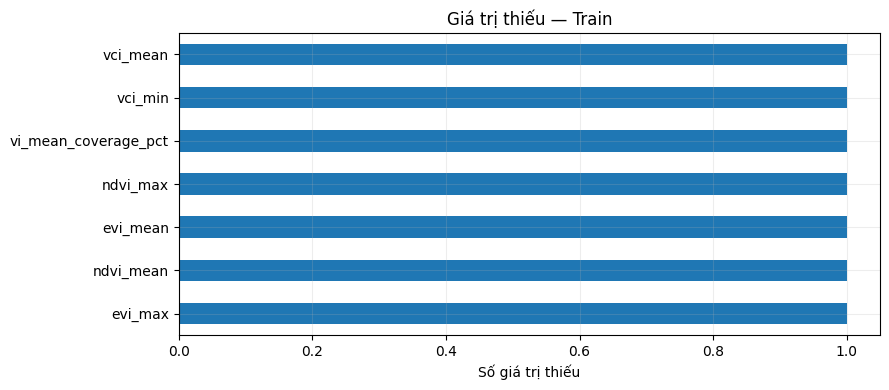

In [5]:
display(train_df[NUMERIC_FEATURES + [TARGET]].describe().T.round(3))
missing = train_df[FEATURES + [TARGET]].isna().sum().sort_values(ascending=False)
display(missing.to_frame('so_gia_tri_thieu_train'))
display(train_df.groupby('mua_vu')[TARGET].agg(['count', 'mean', 'std', 'min', 'max']).round(3))
if (missing > 0).any():
    fig, ax = plt.subplots(figsize=(9, 4))
    missing[missing > 0].sort_values().plot.barh(ax=ax)
    ax.set(xlabel='Số giá trị thiếu', title='Giá trị thiếu — Train')
    plt.tight_layout(); save_fig('01_gia_tri_thieu_train.png'); plt.show()

## 6. Phân phối và xu hướng trên Train

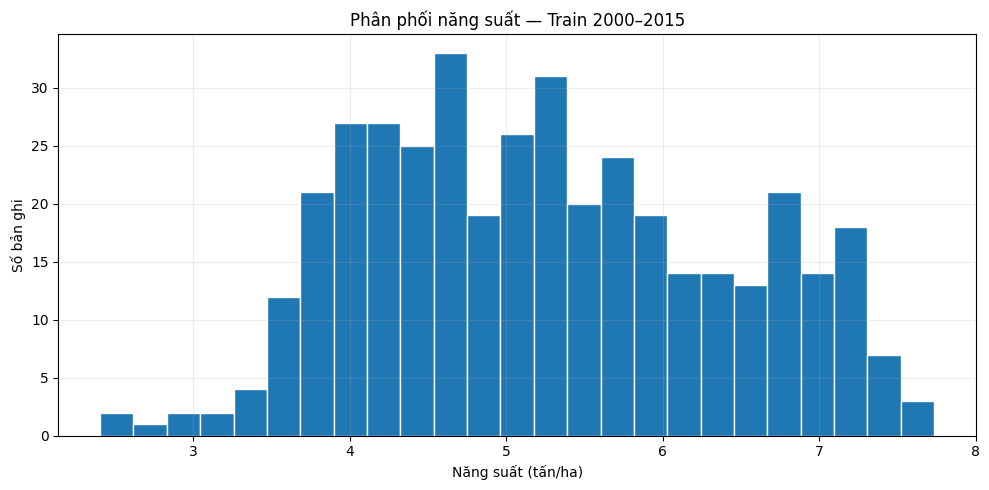

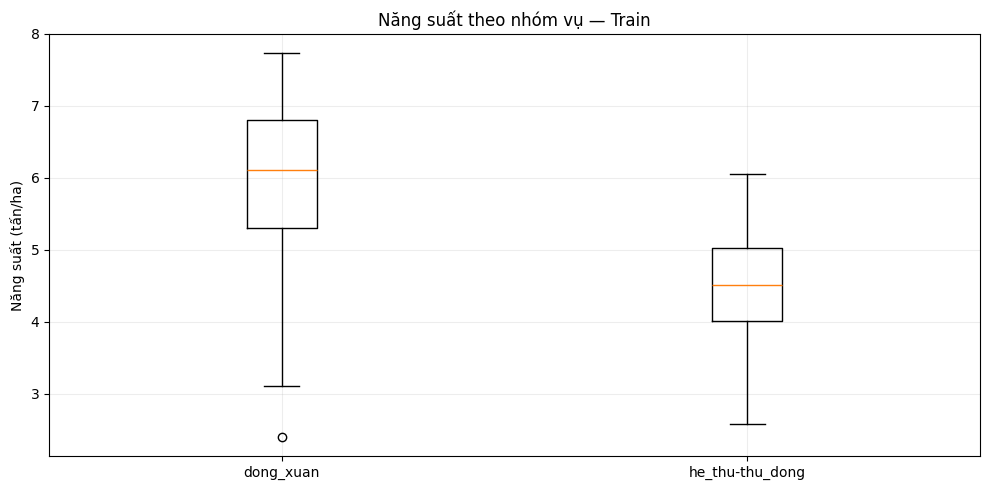

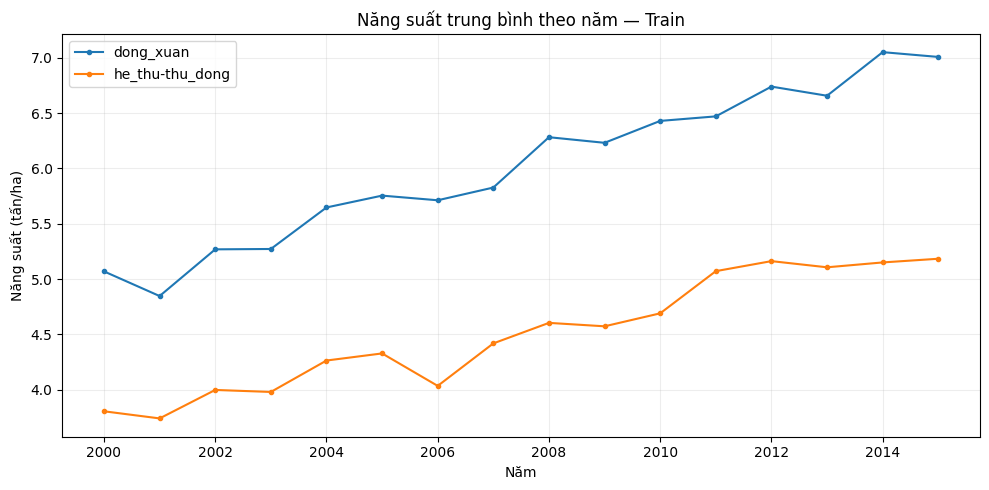

In [6]:
fig, ax = plt.subplots()
ax.hist(y_train, bins=25, edgecolor='white')
ax.set(title='Phân phối năng suất — Train 2000–2015', xlabel='Năng suất (tấn/ha)', ylabel='Số bản ghi')
plt.tight_layout(); save_fig('02_phan_phoi_train.png'); plt.show()

fig, ax = plt.subplots()
seasons = sorted(train_df['mua_vu'].unique())
ax.boxplot([train_df.loc[train_df['mua_vu'] == s, TARGET] for s in seasons], tick_labels=seasons)
ax.set(title='Năng suất theo nhóm vụ — Train', ylabel='Năng suất (tấn/ha)')
plt.tight_layout(); save_fig('03_nang_suat_theo_vu_train.png'); plt.show()

fig, ax = plt.subplots()
yearly = train_df.groupby(['nam', 'mua_vu'])[TARGET].mean().unstack()
for season in yearly.columns:
    ax.plot(yearly.index, yearly[season], marker='o', markersize=3, label=season)
ax.set(title='Năng suất trung bình theo năm — Train', xlabel='Năm', ylabel='Năng suất (tấn/ha)')
ax.legend(); plt.tight_layout(); save_fig('04_xu_huong_train.png'); plt.show()

## Ma trận tương quan và độ tương quan với nhãn

Chỉ tính tương quan trên Train để không dựa vào nhãn của Validation/Test khi diễn giải hoặc lựa chọn thuộc tính. Pearson mô tả quan hệ tuyến tính; Spearman mô tả quan hệ đơn điệu. Cả hai không suy ra quan hệ nhân quả. Các thuộc tính đồng biến theo năm có thể phản ánh xu thế chung.

MỨC ĐỘ TƯƠNG QUAN VỚI NHÃN (Train 2000–2015):


,pearson_r,spearman_rho,abs_pearson
rainfall_sum_mm,-0.647,-0.604,0.647
rainy_months_100mm,-0.623,-0.555,0.623
rainfall_max_month_mm,-0.554,-0.577,0.554
vi_months_available,-0.537,-0.636,0.537
nam,0.489,0.487,0.489
evi_max,0.456,0.450,0.456
evi_mean,0.437,0.479,0.437
vi_months_quality80,-0.421,-0.533,0.421
temperature_min_c,-0.376,-0.368,0.376
vci_mean,0.302,0.342,0.302


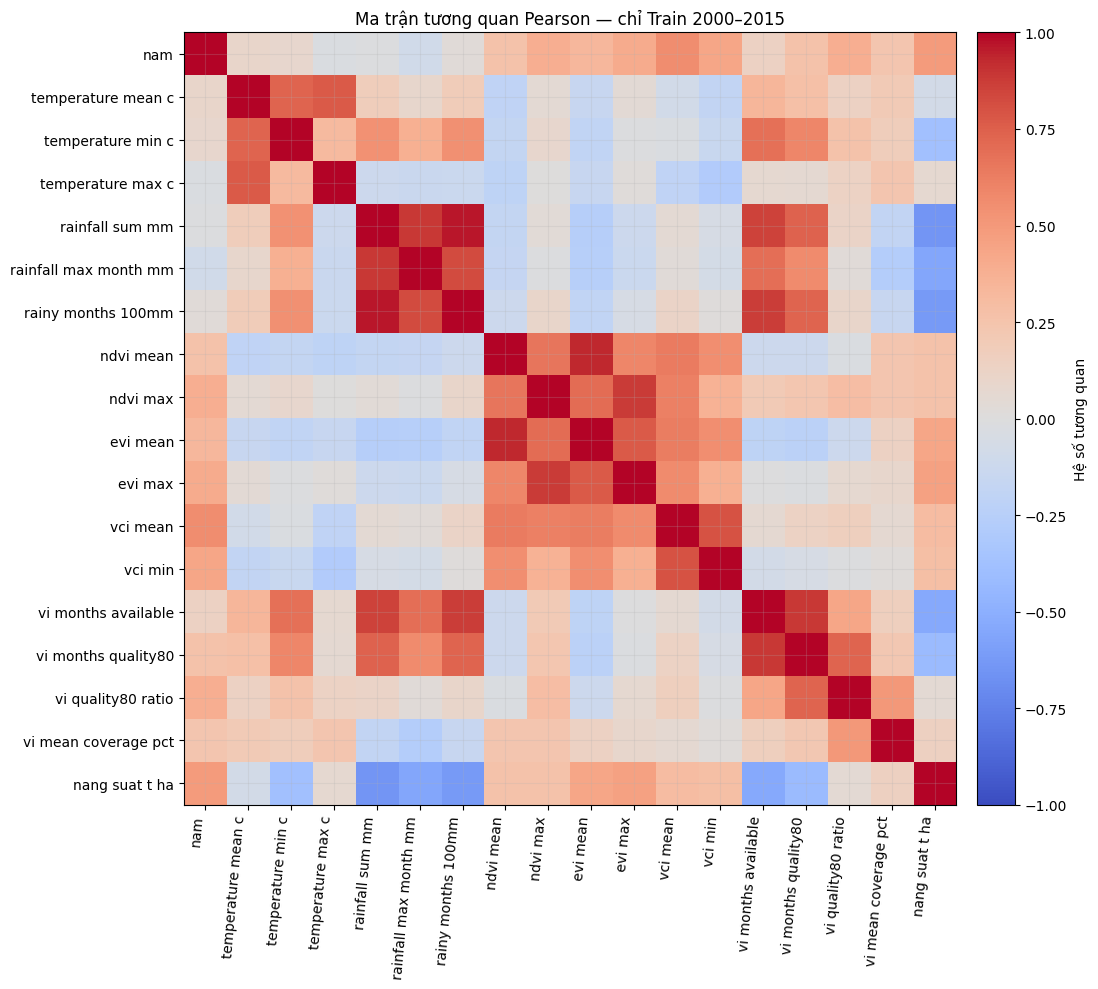

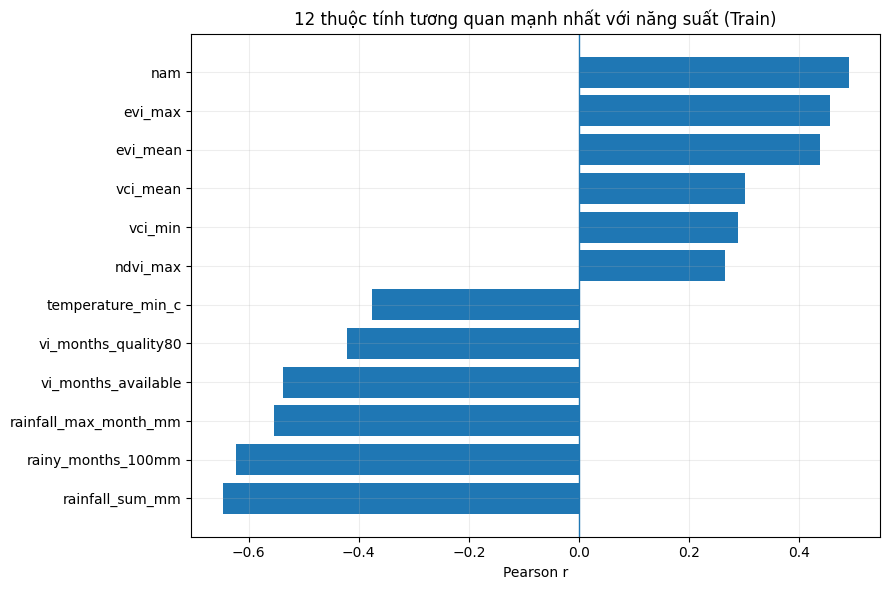

In [7]:
corr_features = NUMERIC_FEATURES + [TARGET]
pearson_matrix = train_df[corr_features].corr(method='pearson')
pearson_target = pearson_matrix[TARGET].drop(TARGET).sort_values(key=lambda s: s.abs(), ascending=False)
spearman_target = train_df[corr_features].corr(method='spearman')[TARGET].drop(TARGET)

corr_table = pd.DataFrame({
    'pearson_r': pearson_target,
    'spearman_rho': spearman_target.reindex(pearson_target.index),
    'abs_pearson': pearson_target.abs(),
}).round(3)
print('MỨC ĐỘ TƯƠNG QUAN VỚI NHÃN (Train 2000–2015):')
display(corr_table)

fig, ax = plt.subplots(figsize=(12, 10))
mat = ax.imshow(pearson_matrix, vmin=-1, vmax=1, cmap='coolwarm')
labels = [c.replace('_', ' ') for c in corr_features]
ax.set_xticks(range(len(labels)), labels=labels, rotation=85, ha='right')
ax.set_yticks(range(len(labels)), labels=labels)
ax.set_title('Ma trận tương quan Pearson — chỉ Train 2000–2015')
fig.colorbar(mat, ax=ax, fraction=0.04, pad=0.02, label='Hệ số tương quan')
plt.tight_layout(); save_fig('05_ma_tran_tuong_quan.png'); plt.show()

fig, ax = plt.subplots(figsize=(9, 6))
top = pearson_target.head(12).sort_values()
ax.barh(top.index, top.values)
ax.axvline(0, linewidth=1)
ax.set(xlabel='Pearson r', title='12 thuộc tính tương quan mạnh nhất với năng suất (Train)')
plt.tight_layout(); save_fig('06_tuong_quan_voi_nhan.png'); plt.show()

## Biểu đồ phân tán của các đặc trưng liên quan đến năng suất

Chọn 4 thuộc tính có |Pearson| lớn nhất trên tập Train. Đường thẳng chỉ là xu hướng tuyến tính, không chứng minh ảnh hưởng nhân quả.

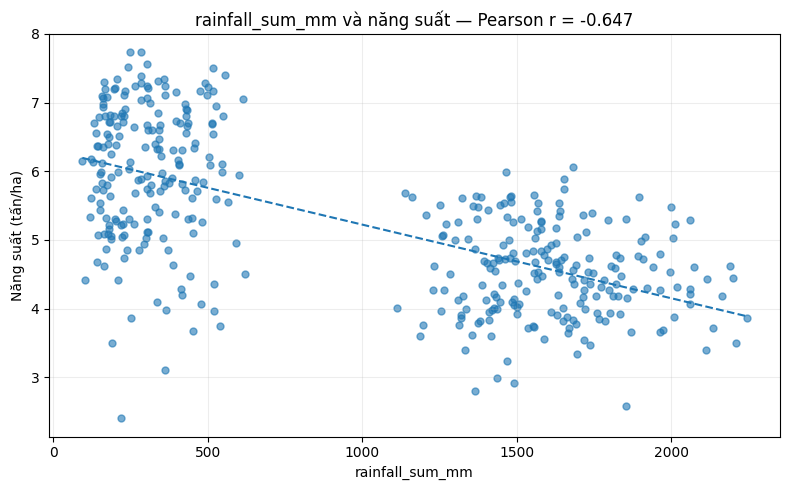

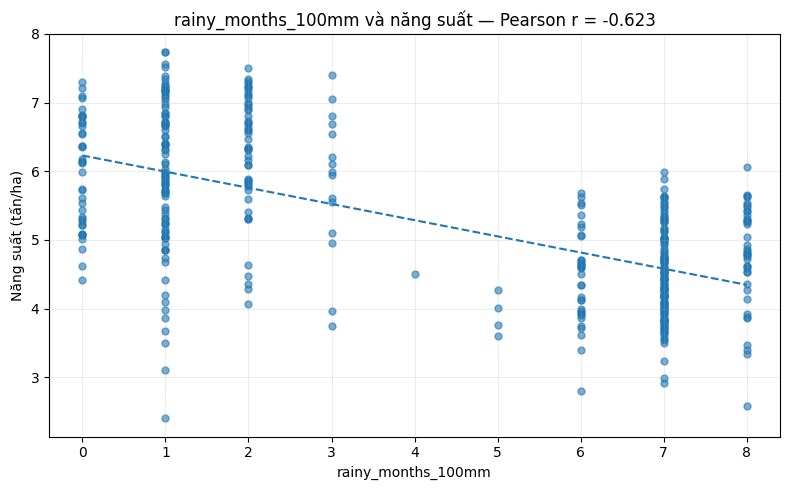

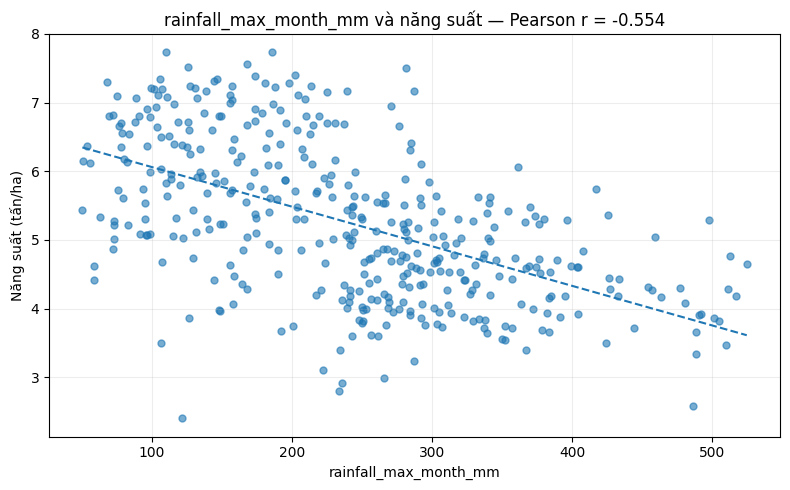

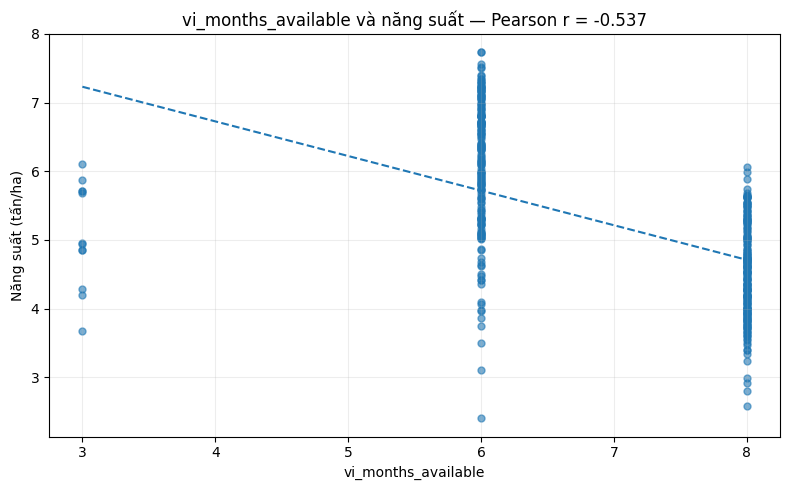

In [8]:
top4 = pearson_target.head(4).index.tolist()
for j, col in enumerate(top4, start=1):
    temp = train_df[[col, TARGET]].dropna()
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.scatter(temp[col], temp[TARGET], alpha=0.6, s=25)
    if temp[col].nunique() > 1:
        m, b = np.polyfit(temp[col], temp[TARGET], 1)
        xx = np.linspace(temp[col].min(), temp[col].max(), 100)
        ax.plot(xx, m * xx + b, linestyle='--')
    ax.set(xlabel=col, ylabel='Năng suất (tấn/ha)',
           title=f'{col} và năng suất — Pearson r = {pearson_target[col]:.3f}')
    plt.tight_layout(); save_fig(f'07_scatter_{j}_{col}.png'); plt.show()

## 5. Tiền xử lý phù hợp từng nhóm mô hình

Tất cả mô hình dùng cùng danh sách 19 đặc trưng thô; khác nhau ở biểu diễn phù hợp với thuật toán:

- **11 base sklearn/XGBoost:** điền trung vị cho biến số, thêm chỉ báo thiếu; One-Hot biến phân loại với `handle_unknown='ignore'`. Trung vị, cột mã hóa và mọi thống kê chỉ học trên tập fit. Giữ cột hoàn toàn thiếu để không mất cấu trúc đầu vào.
- **Bayesian Ridge, SVR, Ridge, Elastic Net:** thêm StandardScaler cho khối số. Khối One-Hot giữ nguyên. Mô hình cây không cần chuẩn hóa số.
- **CatBoost:** NaN số và biến phân loại được xử lý nội bộ; không One-Hot hoặc điền trung vị thủ công.
- **Meta Ridge:** StandardScaler trên đúng 4 cột dự đoán ngoài mẫu rồi Ridge(alpha=10). Scaler này chỉ fit trên dữ liệu dùng học meta learner.

Các Pipeline được clone và fit lại cho từng fold; không fit tiền xử lý trên toàn CSV trước khi chia tập.

In [9]:
def make_preprocessor(scale_numeric=False):
    numeric_steps = [('imputer', SimpleImputer(strategy='median', add_indicator=True,
                                               keep_empty_features=True))]
    if scale_numeric:
        numeric_steps.append(('scaler', StandardScaler()))
    return ColumnTransformer([
        ('numeric', Pipeline(numeric_steps), NUMERIC_FEATURES),
        ('categorical', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CATEGORICAL_FEATURES),
    ], sparse_threshold=0)

def make_pipeline(regressor, scale_numeric=False):
    return Pipeline([('preprocessor', make_preprocessor(scale_numeric)), ('regressor', regressor)])

def evaluate(y_true, pred):
    pred = np.asarray(pred, dtype=float)
    if len(pred) != len(y_true) or not np.isfinite(pred).all():
        raise ValueError('Dự đoán không hợp lệ.')
    return {'MAE_t_ha': float(mean_absolute_error(y_true, pred)),
            'RMSE_t_ha': float(np.sqrt(mean_squared_error(y_true, pred))),
            'R2': float(r2_score(y_true, pred))}

templates = {}
trained_on_train = {}
val_predictions = {}
metric_rows = []
timing_rows = []

def train_and_validate(name, template):
    templates[name] = template
    estimator = clone(template)
    started = perf_counter()
    estimator.fit(X_train, y_train)
    fit_seconds = perf_counter() - started
    train_pred = np.asarray(estimator.predict(X_train), dtype=float)
    started = perf_counter()
    val_pred = np.asarray(estimator.predict(X_val), dtype=float)
    predict_seconds = perf_counter() - started
    trained_on_train[name] = estimator
    val_predictions[name] = val_pred
    rows = [
        {'model': name, 'split': 'train_2000_2015', 'rows': len(y_train), **evaluate(y_train, train_pred)},
        {'model': name, 'split': 'validation_2016_2018', 'rows': len(y_val), **evaluate(y_val, val_pred)},
    ]
    metric_rows.extend(rows)
    timing_rows.append({'model': name, 'stage': 'train_validation',
                        'fit_rows': len(y_train), 'predict_rows': len(y_val),
                        'fit_seconds': fit_seconds, 'predict_seconds': predict_seconds})
    display(pd.DataFrame(rows).round(4))
    print(f'Thời gian fit: {fit_seconds:.3f}s; dự đoán Validation: {predict_seconds:.3f}s')

## 6. Random Forest base

200 cây, các tham số còn lại theo cấu hình cơ sở của thư viện; giữ cây không giới hạn độ sâu. Seed cố định và tối đa 4 luồng CPU.

In [10]:
train_and_validate('RandomForest', make_pipeline(RandomForestRegressor(
    n_estimators=200, random_state=RANDOM_STATE, n_jobs=THREAD_COUNT)))

,model,split,rows,MAE_t_ha,RMSE_t_ha,R2
0,RandomForest,train_2000_2015,399,0.1116,0.1473,0.9830
1,RandomForest,validation_2016_2018,76,0.5241,0.9663,0.2969


Thời gian fit: 0.314s; dự đoán Validation: 0.036s


## 7. Extra Trees base

200 cây ngẫu nhiên hóa; không giới hạn độ sâu. Không chọn tham số theo Validation/Test.

In [11]:
train_and_validate('ExtraTrees', make_pipeline(ExtraTreesRegressor(
    n_estimators=200, random_state=RANDOM_STATE, n_jobs=THREAD_COUNT)))

,model,split,rows,MAE_t_ha,RMSE_t_ha,R2
0,ExtraTrees,train_2000_2015,399,0.0000,0.0000,1.0000
1,ExtraTrees,validation_2016_2018,76,0.4915,0.8576,0.4462


Thời gian fit: 0.208s; dự đoán Validation: 0.037s


## 8. XGBoost base

Cấu hình CPU cố định: 200 cây, depth=6, learning_rate=0.05, histogram và mục tiêu sai số bình phương. Không dừng sớm bằng Validation hoặc Test.

In [12]:
train_and_validate('XGBoost', make_pipeline(XGBRegressor(
    n_estimators=200, max_depth=6, learning_rate=0.05,
    objective='reg:squarederror', tree_method='hist',
    subsample=1.0, colsample_bytree=1.0, reg_lambda=1.0,
    random_state=RANDOM_STATE, n_jobs=THREAD_COUNT, verbosity=0)))

,model,split,rows,MAE_t_ha,RMSE_t_ha,R2
0,XGBoost,train_2000_2015,399,0.0218,0.0316,0.9992
1,XGBoost,validation_2016_2018,76,0.5283,0.9466,0.3254


Thời gian fit: 0.222s; dự đoán Validation: 0.003s


## 9. Decision Tree Regressor base

Một cây đơn không giới hạn độ sâu để làm mốc so sánh với các ensemble. Bảng Train/Validation giúp quan sát nguy cơ quá khớp.

In [13]:
train_and_validate('DecisionTree', make_pipeline(DecisionTreeRegressor(random_state=RANDOM_STATE)))

,model,split,rows,MAE_t_ha,RMSE_t_ha,R2
0,DecisionTree,train_2000_2015,399,0.0000,0.0000,1.0000
1,DecisionTree,validation_2016_2018,76,0.5978,0.9835,0.2716


Thời gian fit: 0.009s; dự đoán Validation: 0.002s


## 10. Bayesian Ridge base

In [14]:
train_and_validate('BayesianRidge', make_pipeline(BayesianRidge(), scale_numeric=True))

,model,split,rows,MAE_t_ha,RMSE_t_ha,R2
0,BayesianRidge,train_2000_2015,399,0.2962,0.3950,0.8774
1,BayesianRidge,validation_2016_2018,76,0.6245,1.0107,0.2309


Thời gian fit: 0.008s; dự đoán Validation: 0.002s


## 11. Gradient Boosting Regressor base

100 cây, learning_rate=0.1, depth=3 theo cấu hình base; seed cố định.

In [15]:
train_and_validate('GradientBoosting', make_pipeline(GradientBoostingRegressor(
    n_estimators=100, learning_rate=0.1, max_depth=3, random_state=RANDOM_STATE)))

,model,split,rows,MAE_t_ha,RMSE_t_ha,R2
0,GradientBoosting,train_2000_2015,399,0.1295,0.1678,0.9779
1,GradientBoosting,validation_2016_2018,76,0.4777,0.8878,0.4066


Thời gian fit: 0.184s; dự đoán Validation: 0.002s


## 12. Hist Gradient Boosting base

100 vòng, learning_rate=0.1. Tắt chia holdout nội bộ ngẫu nhiên cho dừng sớm; giữ đúng lịch sử huấn luyện của từng fold.

In [16]:
train_and_validate('HistGradientBoosting', make_pipeline(HistGradientBoostingRegressor(
    max_iter=100, learning_rate=0.1, early_stopping=False, random_state=RANDOM_STATE)))

,model,split,rows,MAE_t_ha,RMSE_t_ha,R2
0,HistGradientBoosting,train_2000_2015,399,0.0886,0.1298,0.9868
1,HistGradientBoosting,validation_2016_2018,76,0.5477,0.9677,0.2950


Thời gian fit: 0.094s; dự đoán Validation: 0.004s


## 13. Support Vector Regressor base — RBF, C=1, epsilon=0.1

In [17]:
train_and_validate('SVR', make_pipeline(SVR(kernel='rbf', C=1.0, epsilon=0.1), scale_numeric=True))

,model,split,rows,MAE_t_ha,RMSE_t_ha,R2
0,SVR,train_2000_2015,399,0.1831,0.2776,0.9395
1,SVR,validation_2016_2018,76,0.5592,0.9819,0.2741


Thời gian fit: 0.012s; dự đoán Validation: 0.003s


## 14. Ridge base — alpha=1

In [18]:
train_and_validate('Ridge', make_pipeline(Ridge(alpha=1.0), scale_numeric=True))

,model,split,rows,MAE_t_ha,RMSE_t_ha,R2
0,Ridge,train_2000_2015,399,0.2954,0.3938,0.8782
1,Ridge,validation_2016_2018,76,0.6255,1.0103,0.2314


Thời gian fit: 0.007s; dự đoán Validation: 0.002s


## 15. Elastic Net base — alpha=1, l1_ratio=0.5

In [19]:
train_and_validate('ElasticNet', make_pipeline(ElasticNet(
    alpha=1.0, l1_ratio=0.5, max_iter=10000, random_state=RANDOM_STATE), scale_numeric=True))

,model,split,rows,MAE_t_ha,RMSE_t_ha,R2
0,ElasticNet,train_2000_2015,399,0.8363,1.0065,0.2043
1,ElasticNet,validation_2016_2018,76,0.8742,1.1618,-0.0163


Thời gian fit: 0.007s; dự đoán Validation: 0.002s


## 16. Dummy base — dự đoán trung bình Train

In [20]:
train_and_validate('Dummy', make_pipeline(DummyRegressor(strategy='mean')))

,model,split,rows,MAE_t_ha,RMSE_t_ha,R2
0,Dummy,train_2000_2015,399,0.9413,1.1283,0.000
1,Dummy,validation_2016_2018,76,0.9552,1.2439,-0.165


Thời gian fit: 0.006s; dự đoán Validation: 0.002s


## 17. Chọn 4 base learner cho Stacking

Xếp hạng **11 base** bằng MAE Validation 2016–2018 tăng dần; nếu bằng nhau dùng RMSE rồi tên. Chọn đúng 4 mô hình đầu, không dùng điểm Test. CatBoost chạy ở phần tiếp theo như đối chứng riêng, không tham gia chọn 4 base.

Bảng Validation dùng để lựa chọn nên không phải ước lượng hoàn toàn độc lập cho base đứng đầu. Danh sách top 4 được khóa trước khi tạo dự đoán Test.

,model,split,rows,MAE_t_ha,RMSE_t_ha,R2
0,GradientBoosting,validation_2016_2018,76,0.4777,0.8878,0.4066
1,ExtraTrees,validation_2016_2018,76,0.4915,0.8576,0.4462
2,RandomForest,validation_2016_2018,76,0.5241,0.9663,0.2969
3,XGBoost,validation_2016_2018,76,0.5283,0.9466,0.3254
4,HistGradientBoosting,validation_2016_2018,76,0.5477,0.9677,0.2950
5,SVR,validation_2016_2018,76,0.5592,0.9819,0.2741
6,DecisionTree,validation_2016_2018,76,0.5978,0.9835,0.2716
7,BayesianRidge,validation_2016_2018,76,0.6245,1.0107,0.2309
8,Ridge,validation_2016_2018,76,0.6255,1.0103,0.2314
9,ElasticNet,validation_2016_2018,76,0.8742,1.1618,-0.0163


4 base được chọn: ['GradientBoosting', 'ExtraTrees', 'RandomForest', 'XGBoost']
Base tốt nhất trên Validation: GradientBoosting


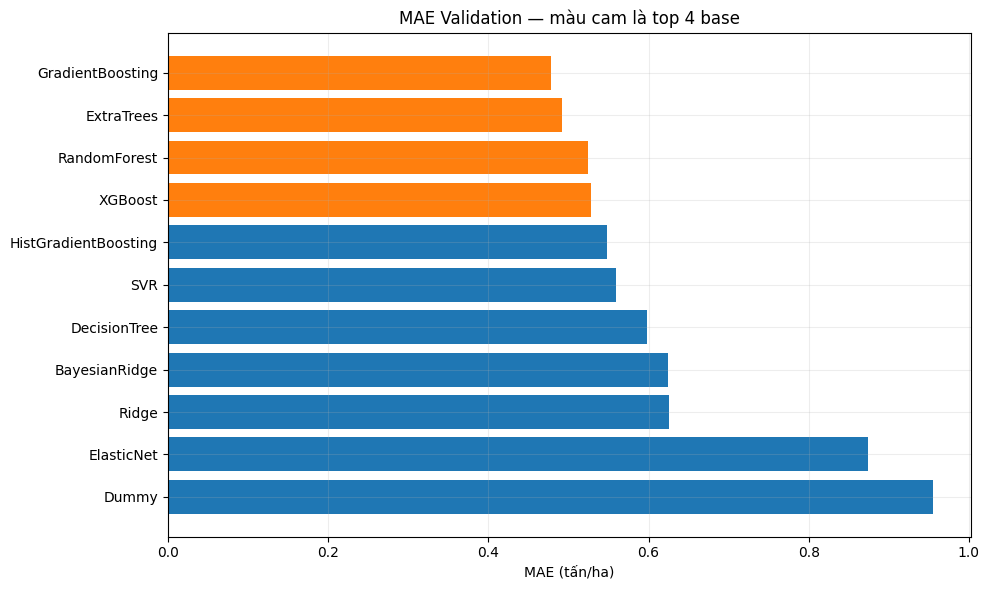

In [21]:
assert list(trained_on_train) == BASE_ORDER
base_validation_metrics = pd.DataFrame([
    row for row in metric_rows if row['split'] == 'validation_2016_2018'
]).sort_values(['MAE_t_ha', 'RMSE_t_ha', 'model']).reset_index(drop=True)
TOP4 = base_validation_metrics.head(4)['model'].tolist()
BEST_BASE = TOP4[0]
assert len(TOP4) == len(set(TOP4)) == 4
assert set(TOP4).issubset(BASE_ORDER)
display(base_validation_metrics.round(4))
print('4 base được chọn:', TOP4)
print('Base tốt nhất trên Validation:', BEST_BASE)

fig, ax = plt.subplots(figsize=(10, 6))
plot_data = base_validation_metrics.iloc[::-1]
ax.barh(plot_data['model'], plot_data['MAE_t_ha'],
        color=['tab:orange' if name in TOP4 else 'tab:blue' for name in plot_data['model']])
ax.set(title='MAE Validation — màu cam là top 4 base', xlabel='MAE (tấn/ha)')
plt.tight_layout(); save_fig('08_base_validation_mae.png'); plt.show()

## 18. Stacking Ensemble — meta learner Ridge Regression

Tạo **76 dự đoán ngoài mẫu** cho từng base đã chọn:

| Năm dự đoán OOF | Lịch sử được phép fit base và tiền xử lý |
|---|---|
| 2016 | 2000–2015 |
| 2017 | 2000–2016 |
| 2018 | 2000–2017 |

Mỗi bản ghi meta có đúng 4 cột dự đoán từ mô hình chưa fit nhãn của chính bản ghi đó. **Không dùng dự đoán trên Train của mô hình đã học chính Train** để học Ridge. Khi tạo OOF, chuẩn VCI 2000–2015 đã có sẵn.

Fit StandardScaler → Ridge(alpha=10) trên 4 cột OOF và nhãn 2016–2018. Việc chọn 4 cột cũng dùng giai đoạn này, nên toàn bộ 2016–2018 là dữ liệu phát triển; không báo R²/MAE trên đó như hiệu năng kiểm định của Stacking. Test sẽ là tập so sánh chung.

Tại bước cuối, fit lại 4 base trên 2000–2018, dự đoán Test rồi đưa 4 dự đoán vào Ridge đã học. Ridge chỉ nhận 4 dự đoán (`passthrough=False` về mặt thiết kế), không nhận thêm đặc trưng gốc.

In [22]:
oof_predictions = pd.DataFrame(index=val_df.index, columns=TOP4, dtype=float)
oof_counts = pd.Series(0, index=val_df.index, dtype=int)
fold_rows = []
for predict_year in OOF_YEARS:
    history = trainval_df.loc[trainval_df['nam'] < predict_year].copy()
    future = val_df.loc[val_df['nam'] == predict_year].copy()
    assert not history.empty and not future.empty
    assert history['nam'].max() < future['nam'].min()
    assert history['nam'].max() <= 2017 and predict_year >= 2016
    history_keys = set(history[['adm1_code', 'nam', 'mua_vu']].itertuples(index=False, name=None))
    future_keys = set(future[['adm1_code', 'nam', 'mua_vu']].itertuples(index=False, name=None))
    assert history_keys.isdisjoint(future_keys)
    fit_X, future_X = prepare_features(history), prepare_features(future)
    for name in TOP4:
        started = perf_counter()
        learner = clone(templates[name])
        learner.fit(fit_X, history[TARGET])
        oof_predictions.loc[future.index, name] = learner.predict(future_X)
        fold_rows.append({'model': name, 'predict_year': predict_year,
                          'fit_year_min': int(history['nam'].min()),
                          'fit_year_max': int(history['nam'].max()),
                          'fit_rows': len(history), 'oof_rows': len(future),
                          'fit_predict_seconds': perf_counter() - started})
    oof_counts.loc[future.index] += 1
assert oof_counts.eq(1).all()
assert np.isfinite(oof_predictions.to_numpy()).all()
assert list(oof_predictions.columns) == TOP4
meta_learner = Pipeline([('scaler', StandardScaler()), ('ridge', Ridge(alpha=META_ALPHA))])
started = perf_counter()
meta_learner.fit(oof_predictions, val_df.loc[oof_predictions.index, TARGET])
meta_fit_seconds = perf_counter() - started
fold_summary = pd.DataFrame(fold_rows)
meta_oof_report = pd.concat([
    val_df[['adm1_code', 'tinh_thanh', 'nam', 'mua_vu', TARGET]].rename(columns={TARGET: 'actual_t_ha'}),
    oof_predictions.add_prefix('oof_'),
], axis=1)
display(fold_summary.round(4))
print('Ridge meta learner đã học:', len(oof_predictions), 'dòng ×', len(TOP4), 'dự đoán OOF.')
print('Không tính điểm Validation cho Stacking trên chính nhãn đã dùng học Ridge.')

,model,predict_year,fit_year_min,fit_year_max,fit_rows,oof_rows,fit_predict_seconds
0,GradientBoosting,2016,2000,2015,399,25,0.1549
1,ExtraTrees,2016,2000,2015,399,25,0.2619
2,RandomForest,2016,2000,2015,399,25,0.3226
3,XGBoost,2016,2000,2015,399,25,0.1770
4,GradientBoosting,2017,2000,2016,424,26,0.1508
5,ExtraTrees,2017,2000,2016,424,26,0.2408
6,RandomForest,2017,2000,2016,424,26,0.3349
7,XGBoost,2017,2000,2016,424,26,0.1609
8,GradientBoosting,2018,2000,2017,450,25,0.1686
9,ExtraTrees,2018,2000,2017,450,25,0.2590


Ridge meta learner đã học: 76 dòng × 4 dự đoán OOF.
Không tính điểm Validation cho Stacking trên chính nhãn đã dùng học Ridge.


## 19. CatBoost — mô hình đối chứng riêng

Một cấu hình base cố định: 500 cây, depth=6, learning_rate=0.05, l2_leaf_reg=3. Không dùng cấu hình 131 cây được chọn ở thí nghiệm cũ và không tìm kiếm thêm. Không `eval_set` hay dừng sớm theo Test. Các dòng fit được sắp theo năm và `has_time=True`.

CatBoost dùng cùng 19 đặc trưng đầu vào, nhưng giữ biểu diễn phân loại và NaN số nguyên bản để tận dụng xử lý nội bộ của thuật toán.

In [23]:
train_and_validate('CatBoost', CatBoostRegressor(
    iterations=500, depth=6, learning_rate=0.05, l2_leaf_reg=3.0,
    loss_function='RMSE', random_seed=RANDOM_STATE, thread_count=THREAD_COUNT,
    task_type='CPU', cat_features=CATEGORICAL_FEATURES, nan_mode='Min',
    has_time=True, boosting_type='Ordered', allow_writing_files=False, verbose=False,
))
validation_metrics = pd.DataFrame([
    row for row in metric_rows if row['split'] == 'validation_2016_2018'
]).sort_values(['MAE_t_ha', 'RMSE_t_ha', 'model']).reset_index(drop=True)
display(validation_metrics.round(4))
print('CatBoost chỉ dùng để đối chiếu; top 4 Stacking giữ nguyên:', TOP4)

,model,split,rows,MAE_t_ha,RMSE_t_ha,R2
0,CatBoost,train_2000_2015,399,0.3066,0.4019,0.8731
1,CatBoost,validation_2016_2018,76,0.5070,0.8802,0.4166


Thời gian fit: 6.007s; dự đoán Validation: 0.001s


,model,split,rows,MAE_t_ha,RMSE_t_ha,R2
0,GradientBoosting,validation_2016_2018,76,0.4777,0.8878,0.4066
1,ExtraTrees,validation_2016_2018,76,0.4915,0.8576,0.4462
2,CatBoost,validation_2016_2018,76,0.5070,0.8802,0.4166
3,RandomForest,validation_2016_2018,76,0.5241,0.9663,0.2969
4,XGBoost,validation_2016_2018,76,0.5283,0.9466,0.3254
5,HistGradientBoosting,validation_2016_2018,76,0.5477,0.9677,0.2950
6,SVR,validation_2016_2018,76,0.5592,0.9819,0.2741
7,DecisionTree,validation_2016_2018,76,0.5978,0.9835,0.2716
8,BayesianRidge,validation_2016_2018,76,0.6245,1.0107,0.2309
9,Ridge,validation_2016_2018,76,0.6255,1.0103,0.2314


CatBoost chỉ dùng để đối chiếu; top 4 Stacking giữ nguyên: ['GradientBoosting', 'ExtraTrees', 'RandomForest', 'XGBoost']


## 20. Fit lại trên 2000–2018 và đánh giá 13 mô hình trên Test

Fit lại cả 11 base và CatBoost trên **cùng 475 dòng Train+Validation**. Không dùng nhãn Test trong fit, tiền xử lý, dừng sớm hoặc chọn thành phần.

Stacking dùng 4 dự đoán Test từ 4 base đã fit lại và Ridge từ phần 18. Mô hình đơn được fit trực tiếp trên lịch sử 2000–2018; Stacking còn có thêm lớp kết hợp được học từ dự đoán ngoài mẫu của cùng lịch sử đó.

Bảng này là kết quả dự đoán đồng thời 2019–2022 sau khi fit đến 2018, không phải tái huấn luyện hằng năm. Tất cả chỉ số Test được tính trên cùng 104 dòng.

In [24]:
assert set(templates) == set(BASE_ORDER + ['CatBoost'])
assert len(TOP4) == 4
final_models = {}
test_predictions = {}
X_test, y_test = prepare_features(test_df), test_df[TARGET]
for name in BASE_ORDER + ['CatBoost']:
    estimator = clone(templates[name])
    started = perf_counter()
    estimator.fit(X_trainval, y_trainval)
    fit_seconds = perf_counter() - started
    started = perf_counter()
    test_predictions[name] = np.asarray(estimator.predict(X_test), dtype=float)
    predict_seconds = perf_counter() - started
    final_models[name] = estimator
    timing_rows.append({'model': name, 'stage': 'final_fit_test',
                        'fit_rows': len(y_trainval), 'predict_rows': len(y_test),
                        'fit_seconds': fit_seconds, 'predict_seconds': predict_seconds})

stack_test_input = pd.DataFrame({name: test_predictions[name] for name in TOP4}, index=test_df.index)
started = perf_counter()
test_predictions[STACK_NAME] = meta_learner.predict(stack_test_input)
stack_meta_predict_seconds = perf_counter() - started
timing_rows.append({'model': STACK_NAME, 'stage': 'meta_only',
                    'fit_rows': len(oof_predictions), 'predict_rows': len(y_test),
                    'fit_seconds': meta_fit_seconds, 'predict_seconds': stack_meta_predict_seconds})
# Dòng thời gian meta_only chưa bao gồm chi phí fit OOF và chạy 4 base; xem fold_summary.
test_metrics = pd.DataFrame([
    {'model': name, 'split': 'test_2019_2022', 'rows': len(y_test),
     **evaluate(y_test, test_predictions[name])}
    for name in MODEL_ORDER
])
assert len(test_metrics) == 13 and test_metrics['rows'].eq(104).all()
metrics_all = pd.concat([pd.DataFrame(metric_rows), test_metrics], ignore_index=True)
timing_df = pd.DataFrame(timing_rows)
display(test_metrics.sort_values(['MAE_t_ha', 'RMSE_t_ha', 'model']).round(4))
print('4 thành phần Stacking đã chọn trước Test:', TOP4)
print('Không đổi thành phần, tham số hoặc meta learner theo bảng Test.')

,model,split,rows,MAE_t_ha,RMSE_t_ha,R2
4,BayesianRidge,test_2019_2022,104,0.3595,0.6964,0.6331
8,Ridge,test_2019_2022,104,0.3602,0.6935,0.6361
7,SVR,test_2019_2022,104,0.4367,0.7479,0.5768
12,CatBoost,test_2019_2022,104,0.4410,0.7025,0.6266
1,ExtraTrees,test_2019_2022,104,0.5054,0.8130,0.5000
5,GradientBoosting,test_2019_2022,104,0.5187,0.7294,0.5975
6,HistGradientBoosting,test_2019_2022,104,0.5462,0.7838,0.5352
0,RandomForest,test_2019_2022,104,0.5472,0.7831,0.5360
2,XGBoost,test_2019_2022,104,0.5650,0.8329,0.4751
11,StackingTop4Ridge,test_2019_2022,104,0.6130,0.8437,0.4615


4 thành phần Stacking đã chọn trước Test: ['GradientBoosting', 'ExtraTrees', 'RandomForest', 'XGBoost']
Không đổi thành phần, tham số hoặc meta learner theo bảng Test.


## 21. Stacking có hiệu quả không?

Đối chiếu Stacking với từng mô hình đơn trên Test. Cột chênh lệch được quy ước để **số dương luôn là Stacking tốt hơn**:

- `MAE_reduction = MAE_mô_hình_đơn − MAE_Stacking`.
- `RMSE_reduction = RMSE_mô_hình_đơn − RMSE_Stacking`.
- `R2_gain = R²_Stacking − R²_mô_hình_đơn`.
- Phần trăm giảm MAE dùng MAE mô hình đơn làm mẫu số.

Đối chứng chính là **base tốt nhất được chọn bằng Validation**, không chọn đối chứng theo Test. Đồng thời báo riêng so sánh với CatBoost và đầy đủ 11 base, tránh kết luận chỉ từ việc thắng Dummy. Nếu một chỉ số cải thiện nhưng chỉ số khác giảm, báo cả hai.

In [25]:
test_by_name = test_metrics.set_index('model')
stack_scores = test_by_name.loc[STACK_NAME]
comparison_rows = []
for name in BASE_ORDER + ['CatBoost']:
    other = test_by_name.loc[name]
    mae_reduction = float(other['MAE_t_ha'] - stack_scores['MAE_t_ha'])
    comparison_rows.append({
        'comparator': name, 'is_top4': name in TOP4,
        'best_base_on_validation': name == BEST_BASE,
        'comparator_MAE_t_ha': float(other['MAE_t_ha']),
        'stacking_MAE_t_ha': float(stack_scores['MAE_t_ha']),
        'MAE_reduction_t_ha': mae_reduction,
        'MAE_reduction_pct': 100.0 * mae_reduction / float(other['MAE_t_ha']) if other['MAE_t_ha'] > 0 else np.nan,
        'RMSE_reduction_t_ha': float(other['RMSE_t_ha'] - stack_scores['RMSE_t_ha']),
        'R2_gain': float(stack_scores['R2'] - other['R2']),
    })
stacking_comparison = pd.DataFrame(comparison_rows)
display(stacking_comparison.round(4))
for name in [BEST_BASE, 'CatBoost']:
    row = stacking_comparison.set_index('comparator').loc[name]
    direction = 'giảm' if row['MAE_reduction_t_ha'] > 0 else ('tăng' if row['MAE_reduction_t_ha'] < 0 else 'không đổi')
    print(f"So với {name}: MAE Stacking {direction} {abs(row['MAE_reduction_pct']):.2f}%; "
          f"chênh RMSE={row['RMSE_reduction_t_ha']:+.4f}; chênh R²={row['R2_gain']:+.4f}.")
print(f"Stacking có MAE thấp hơn {(stacking_comparison['MAE_reduction_t_ha'] > 0).sum()}/12 mô hình đơn trên giai đoạn Test này.")
print('Đây là kết quả thực nghiệm của một giai đoạn; chưa kiểm định ý nghĩa thống kê hoặc tối ưu tham số.')

,comparator,is_top4,best_base_on_validation,comparator_MAE_t_ha,stacking_MAE_t_ha,MAE_reduction_t_ha,MAE_reduction_pct,RMSE_reduction_t_ha,R2_gain
0,RandomForest,True,False,0.5472,0.613,-0.0658,-12.0200,-0.0605,-0.0745
1,ExtraTrees,True,False,0.5054,0.613,-0.1076,-21.2983,-0.0307,-0.0384
2,XGBoost,True,False,0.5650,0.613,-0.0480,-8.4923,-0.0107,-0.0136
3,DecisionTree,False,False,0.6491,0.613,0.0361,5.5650,0.1239,0.1697
4,BayesianRidge,False,False,0.3595,0.613,-0.2535,-70.5289,-0.1473,-0.1716
5,GradientBoosting,True,True,0.5187,0.613,-0.0943,-18.1817,-0.1142,-0.1360
6,HistGradientBoosting,False,False,0.5462,0.613,-0.0668,-12.2341,-0.0598,-0.0737
7,SVR,False,False,0.4367,0.613,-0.1763,-40.3734,-0.0958,-0.1153
8,Ridge,False,False,0.3602,0.613,-0.2528,-70.1848,-0.1502,-0.1746
9,ElasticNet,False,False,1.0429,0.613,0.4299,41.2207,0.4612,0.7496


So với GradientBoosting: MAE Stacking tăng 18.18%; chênh RMSE=-0.1142; chênh R²=-0.1360.
So với CatBoost: MAE Stacking tăng 39.01%; chênh RMSE=-0.1412; chênh R²=-0.1651.
Stacking có MAE thấp hơn 3/12 mô hình đơn trên giai đoạn Test này.
Đây là kết quả thực nghiệm của một giai đoạn; chưa kiểm định ý nghĩa thống kê hoặc tối ưu tham số.


## 22. Trực quan hóa so sánh Test và chênh lệch so với Stacking

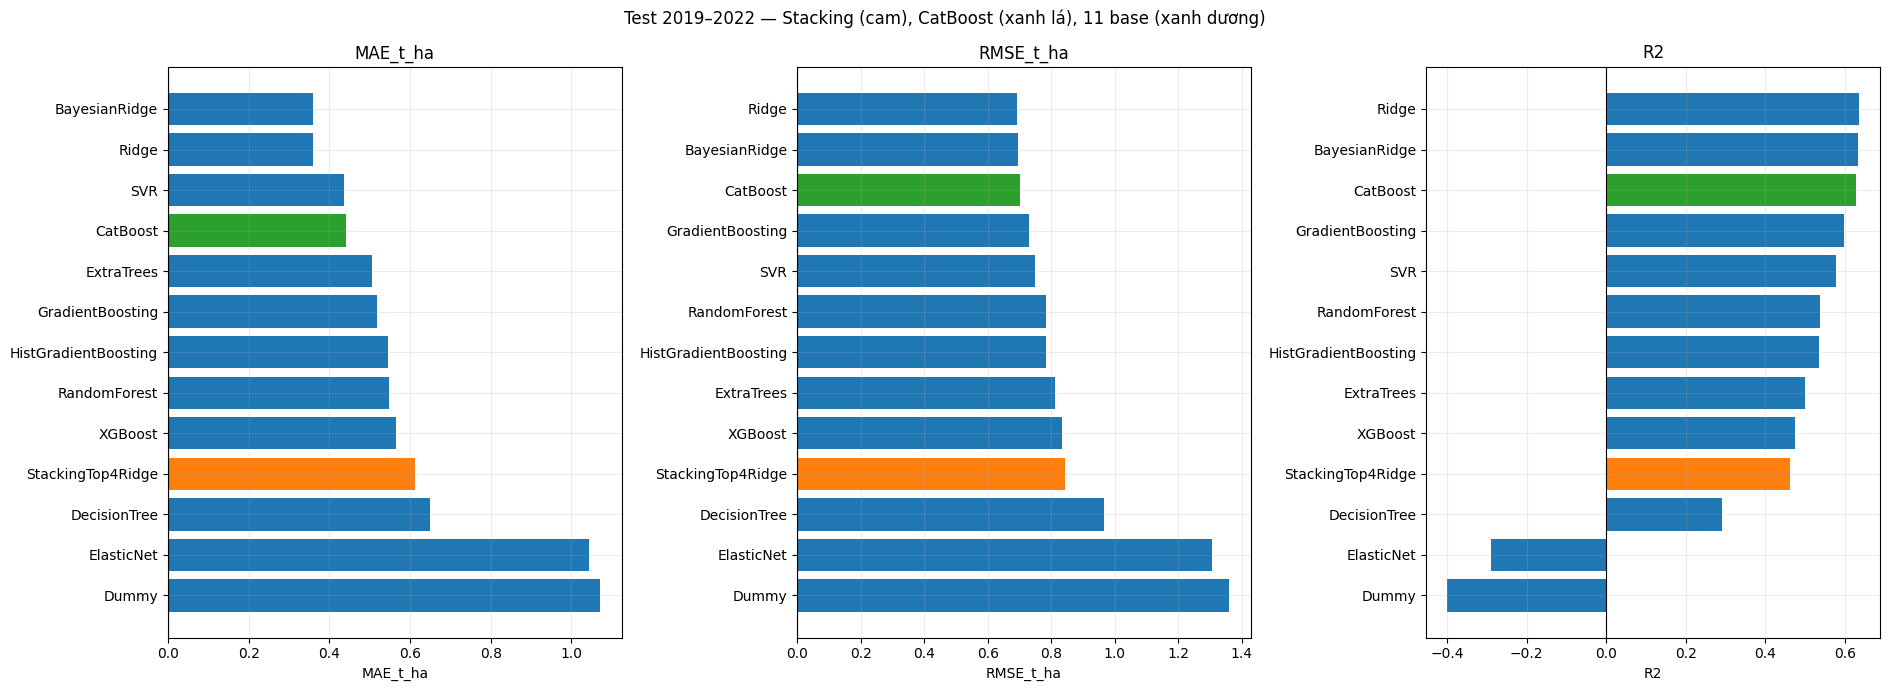

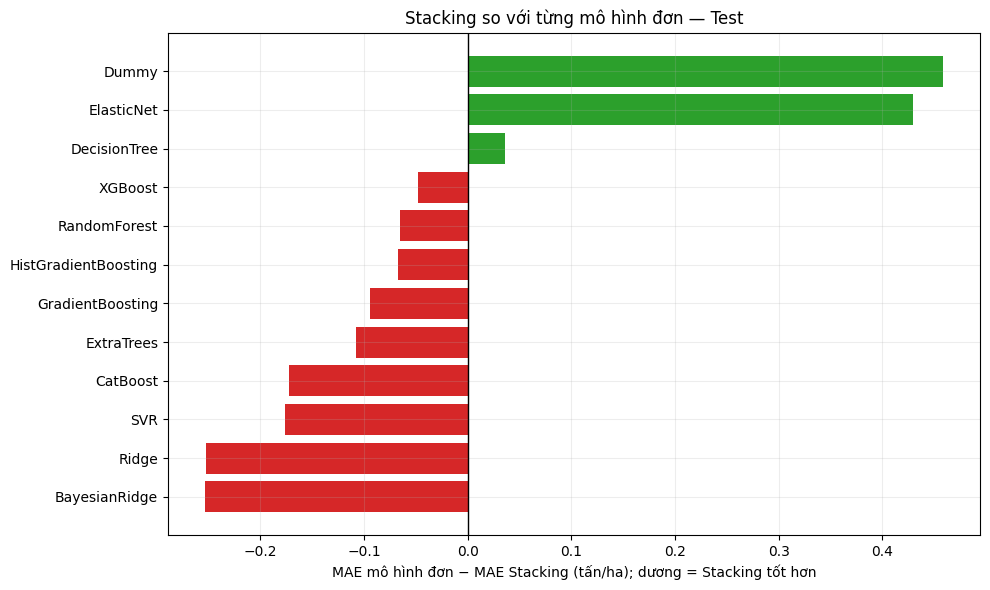

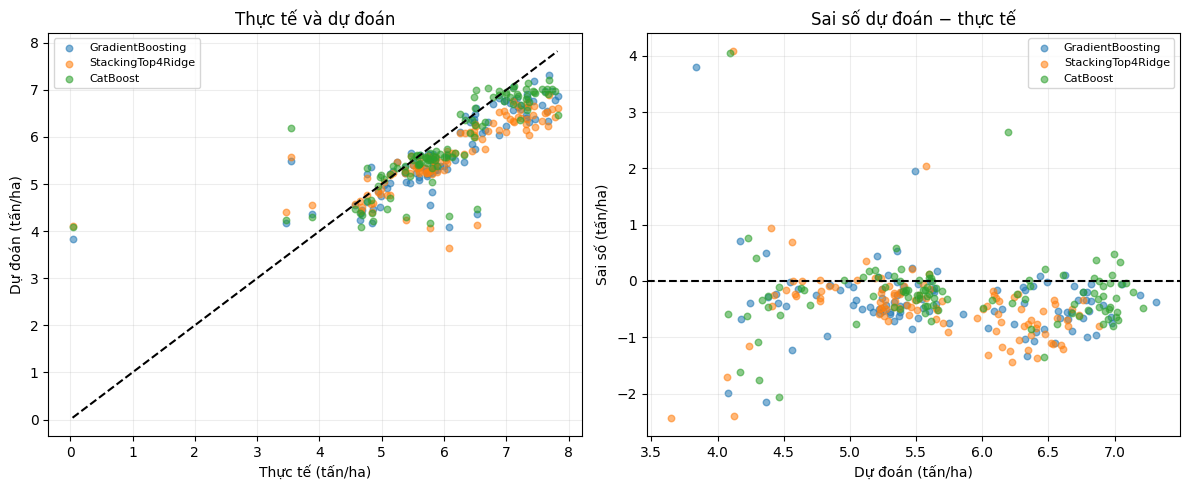

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(19, 7))
for ax, metric in zip(axes, ['MAE_t_ha', 'RMSE_t_ha', 'R2']):
    chart = test_metrics.sort_values(metric, ascending=(metric == 'R2'))
    colors = ['tab:orange' if name == STACK_NAME else ('tab:green' if name == 'CatBoost' else 'tab:blue')
              for name in chart['model']]
    ax.barh(chart['model'], chart[metric], color=colors)
    ax.axvline(0, linewidth=0.8, color='black')
    ax.set(title=metric, xlabel=metric)
fig.suptitle('Test 2019–2022 — Stacking (cam), CatBoost (xanh lá), 11 base (xanh dương)')
plt.tight_layout(); save_fig('09_all_models_test_metrics.png'); plt.show()

fig, ax = plt.subplots(figsize=(10, 6))
chart = stacking_comparison.sort_values('MAE_reduction_t_ha')
ax.barh(chart['comparator'], chart['MAE_reduction_t_ha'],
        color=['tab:green' if value > 0 else 'tab:red' for value in chart['MAE_reduction_t_ha']])
ax.axvline(0, color='black', linewidth=1)
ax.set(title='Stacking so với từng mô hình đơn — Test',
       xlabel='MAE mô hình đơn − MAE Stacking (tấn/ha); dương = Stacking tốt hơn')
plt.tight_layout(); save_fig('10_stacking_mae_improvement.png'); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name in [BEST_BASE, STACK_NAME, 'CatBoost']:
    prediction = test_predictions[name]
    axes[0].scatter(y_test, prediction, alpha=0.55, s=22, label=name)
    axes[1].scatter(prediction, prediction - y_test.to_numpy(), alpha=0.55, s=22, label=name)
lo = min(float(y_test.min()), min(float(np.min(test_predictions[name])) for name in [BEST_BASE, STACK_NAME, 'CatBoost']))
hi = max(float(y_test.max()), max(float(np.max(test_predictions[name])) for name in [BEST_BASE, STACK_NAME, 'CatBoost']))
axes[0].plot([lo, hi], [lo, hi], '--', color='black')
axes[0].set(title='Thực tế và dự đoán', xlabel='Thực tế (tấn/ha)', ylabel='Dự đoán (tấn/ha)')
axes[1].axhline(0, linestyle='--', color='black')
axes[1].set(title='Sai số dự đoán − thực tế', xlabel='Dự đoán (tấn/ha)', ylabel='Sai số (tấn/ha)')
for ax in axes: ax.legend(fontsize=8)
plt.tight_layout(); save_fig('11_prediction_residuals.png'); plt.show()

## 23. Dự đoán từng dòng và sai số theo năm, vụ, tỉnh

In [27]:
prediction_df = test_df[['adm1_code', 'tinh_thanh', 'nam', 'mua_vu']].copy()
prediction_df['actual_t_ha'] = y_test.to_numpy()
for name in MODEL_ORDER:
    prediction_df[f'prediction_{name}_t_ha'] = test_predictions[name]
    prediction_df[f'abs_error_{name}_t_ha'] = np.abs(test_predictions[name] - y_test.to_numpy())
group_rows = []
for field in ['nam', 'mua_vu', 'tinh_thanh']:
    for value, indices in test_df.groupby(field).groups.items():
        for name in MODEL_ORDER:
            group_rows.append({'model': name, 'group_by': field, 'group': str(value),
                               'rows': len(indices),
                               **evaluate(y_test.loc[indices], np.asarray(test_predictions[name])[indices])})
group_metrics = pd.DataFrame(group_rows)
display(group_metrics.loc[(group_metrics['group_by'] == 'nam') &
                          group_metrics['model'].isin([BEST_BASE, STACK_NAME, 'CatBoost'])].round(4))

,model,group_by,group,rows,MAE_t_ha,RMSE_t_ha,R2
5,GradientBoosting,nam,2019,26,0.2776,0.3901,0.7923
11,StackingTop4Ridge,nam,2019,26,0.3639,0.4827,0.6819
12,CatBoost,nam,2019,26,0.2420,0.3429,0.8395
18,GradientBoosting,nam,2020,26,0.7068,1.0321,0.5867
24,StackingTop4Ridge,nam,2020,26,0.7706,1.1243,0.5096
25,CatBoost,nam,2020,26,0.6571,1.0896,0.5394
31,GradientBoosting,nam,2021,26,0.5014,0.6433,0.5415
37,StackingTop4Ridge,nam,2021,26,0.6370,0.7966,0.2971
38,CatBoost,nam,2021,26,0.4709,0.6257,0.5663
44,GradientBoosting,nam,2022,26,0.5888,0.7049,0.4372


## 24. Chọn mô hình bằng top 3 của từng chỉ số; chỉ lưu một mô hình

**MAE, RMSE và R² đều được xét:** MAE mô tả sai số tuyệt đối trung bình; RMSE nhạy hơn với sai số lớn; R² mô tả mức giải thích biến thiên của nhãn. Không fit lại bằng nhãn Test.

Quy tắc cố định để chọn mô hình được lưu từ cả 13 ứng viên:

1. Lấy **đúng 3 mô hình** có MAE thấp nhất, 3 mô hình có RMSE thấp nhất và 3 mô hình có R² cao nhất. Mỗi lần xuất hiện được 1 phiếu; mỗi mô hình nhận từ 0 đến 3 phiếu.
2. Chọn mô hình có **tổng số lần xuất hiện cao nhất**. Không cộng trực tiếp các chỉ số có đơn vị/thang đo khác nhau.
3. Nếu bằng số lần xuất hiện, **ưu tiên MAE thấp hơn**; nếu MAE bằng nhau, xét RMSE thấp hơn, R² cao hơn rồi tên mô hình để kết quả xác định.
4. Nếu các điểm bằng nhau tại ranh giới top 3 của một chỉ số, dùng thứ tự MAE → RMSE → R² → tên (bỏ qua chỉ số chính đã xét) để vẫn lấy đúng 3 mô hình. Không mở rộng thành top 4 hoặc nhiều hơn khi hòa điểm.

Bảng top 3 riêng, thứ hạng từng chỉ số, các cờ thuộc top 3 và tổng số phiếu được hiển thị/xuất CSV. Quy tắc này chỉ chọn **mô hình cuối cùng để lưu**; 4 base của Stacking vẫn được chọn bằng Validation như phần 17.

**Cách diễn giải:** trên cùng các dòng và nhãn, R² = 1 − n × RMSE² / Σ(y − ȳ)², nên RMSE và R² cho cùng thứ tự khi nhãn có biến thiên. Vì vậy đây là quy tắc bỏ phiếu theo yêu cầu, không phải ba nguồn bằng chứng độc lập; ưu tiên MAE được áp dụng khi hòa phiếu, không ghi đè một mô hình có nhiều phiếu hơn.

Chỉ xuất `rice_best_model.joblib` và metadata. Với mô hình đơn, file chứa đúng mô hình đó và tiền xử lý; nếu Stacking được chọn, file chứa đúng 4 base thành phần cùng Ridge cần cho suy luận. Các bảng/biểu đồ so sánh vẫn được lưu đầy đủ. Chỉ dọn các file mô hình cũ đã liệt kê sau khi kiểm tra nạp lại thành công.

**Giới hạn lựa chọn:** Test 2019–2022 được dùng chọn mô hình để lưu. Chỉ số của mô hình thắng có thiên lệch lựa chọn; cần dữ liệu mới để đánh giá độc lập. Test không tham gia fit, chọn 4 thành phần Stacking hoặc tinh chỉnh siêu tham số.

TOP 3 RIÊNG CHO MAE, RMSE VÀ R²:


,metric,metric_rank,model,MAE_t_ha,RMSE_t_ha,R2
0,MAE_t_ha,1,BayesianRidge,0.3595,0.6964,0.6331
1,MAE_t_ha,2,Ridge,0.3602,0.6935,0.6361
2,MAE_t_ha,3,SVR,0.4367,0.7479,0.5768
3,RMSE_t_ha,1,Ridge,0.3602,0.6935,0.6361
4,RMSE_t_ha,2,BayesianRidge,0.3595,0.6964,0.6331
5,RMSE_t_ha,3,CatBoost,0.4410,0.7025,0.6266
6,R2,1,Ridge,0.3602,0.6935,0.6361
7,R2,2,BayesianRidge,0.3595,0.6964,0.6331
8,R2,3,CatBoost,0.4410,0.7025,0.6266


TỔNG HỢP SỐ LẦN XUẤT HIỆN; HÒA PHIẾU ƯU TIÊN MAE:


,rank,model,split,rows,MAE_t_ha,RMSE_t_ha,R2,top3_appearances,rank_MAE_t_ha,top3_MAE_t_ha,rank_RMSE_t_ha,top3_RMSE_t_ha,rank_R2,top3_R2,selected_for_saving
0,1,BayesianRidge,test_2019_2022,104,0.3595,0.6964,0.6331,3,1,True,2,True,2,True,True
1,2,Ridge,test_2019_2022,104,0.3602,0.6935,0.6361,3,2,True,1,True,1,True,False
2,3,CatBoost,test_2019_2022,104,0.4410,0.7025,0.6266,2,4,False,3,True,3,True,False
3,4,SVR,test_2019_2022,104,0.4367,0.7479,0.5768,1,3,True,5,False,5,False,False
4,5,ExtraTrees,test_2019_2022,104,0.5054,0.8130,0.5000,0,5,False,8,False,8,False,False
5,6,GradientBoosting,test_2019_2022,104,0.5187,0.7294,0.5975,0,6,False,4,False,4,False,False
6,7,HistGradientBoosting,test_2019_2022,104,0.5462,0.7838,0.5352,0,7,False,7,False,7,False,False
7,8,RandomForest,test_2019_2022,104,0.5472,0.7831,0.5360,0,8,False,6,False,6,False,False
8,9,XGBoost,test_2019_2022,104,0.5650,0.8329,0.4751,0,9,False,9,False,9,False,False
9,10,StackingTop4Ridge,test_2019_2022,104,0.6130,0.8437,0.4615,0,10,False,10,False,10,False,False


Mô hình được chọn: BayesianRidge; xuất hiện 3/3 top.


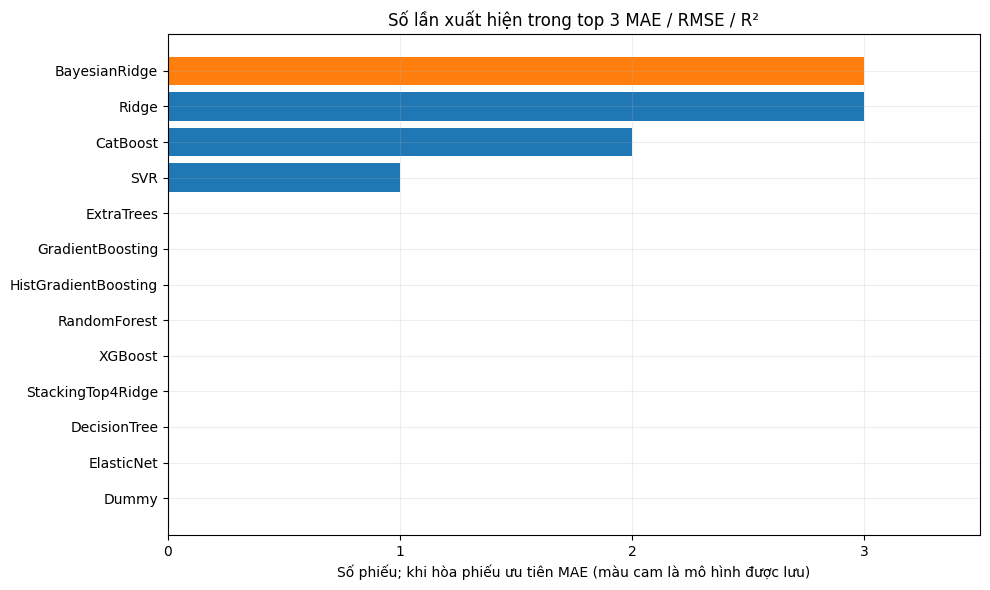

Mô hình được chọn bằng top 3 từng chỉ số, hòa phiếu ưu tiên MAE: BayesianRidge
Chỉ lưu mô hình được chọn: /workspace/rice_yield_estimation/models/model_comparison/rice_best_model.joblib
Metadata: /workspace/rice_yield_estimation/models/model_comparison/rice_best_model_metadata.json
Báo cáo: /workspace/rice_yield_estimation/reports/model_comparison


In [28]:
def rank_models_by_top3(metrics, top_k=3):
    metric_directions = {'MAE_t_ha': True, 'RMSE_t_ha': True, 'R2': False}
    required = ['model', *metric_directions]
    if not set(required).issubset(metrics.columns):
        raise ValueError('Bảng so sánh phải có model, MAE_t_ha, RMSE_t_ha và R2.')
    if metrics['model'].isna().any() or metrics['model'].duplicated().any():
        raise ValueError('Mỗi mô hình phải có đúng một dòng chỉ số.')
    if not isinstance(top_k, int) or top_k < 1 or len(metrics) < top_k:
        raise ValueError('Cần đủ mô hình cho top_k nguyên dương.')
    if not np.isfinite(metrics[list(metric_directions)].to_numpy(dtype=float)).all():
        raise ValueError('Các chỉ số phải hữu hạn; không bỏ phiếu với NaN hoặc vô cực.')
    ranking = metrics.copy()
    ranking['top3_appearances'] = 0
    top_frames = []
    for metric, ascending in metric_directions.items():
        # Khi điểm chỉ số chính hòa, MAE là ưu tiên phụ đầu tiên nếu chưa được xét.
        tie_metrics = [key for key in metric_directions if key != metric]
        sort_columns = [metric, *tie_metrics, 'model']
        sort_directions = [ascending, *[metric_directions[key] for key in tie_metrics], True]
        ordered = metrics.sort_values(sort_columns, ascending=sort_directions, kind='stable')
        positions = {name: position for position, name in enumerate(ordered['model'], start=1)}
        ranking[f'rank_{metric}'] = ranking['model'].map(positions).astype(int)
        in_top = ranking[f'rank_{metric}'].le(top_k)
        ranking[f'top3_{metric}'] = in_top
        ranking['top3_appearances'] += in_top.astype(int)
        leaders = ordered.head(top_k).copy()
        leaders.insert(0, 'metric', metric)
        leaders.insert(1, 'metric_rank', np.arange(1, top_k + 1))
        top_frames.append(leaders)
    ranking = ranking.sort_values(
        ['top3_appearances', 'MAE_t_ha', 'RMSE_t_ha', 'R2', 'model'],
        ascending=[False, True, True, False, True], kind='stable',
    ).reset_index(drop=True)
    ranking.insert(0, 'rank', np.arange(1, len(ranking) + 1))
    ranking['selected_for_saving'] = ranking['rank'].eq(1)
    return ranking, pd.concat(top_frames, ignore_index=True)

ranking_df, top3_by_metric = rank_models_by_top3(test_metrics, top_k=3)
BEST_NAME = ranking_df.loc[0, 'model']
BEST_SCORES = ranking_df.iloc[0][['MAE_t_ha', 'RMSE_t_ha', 'R2']].to_dict()
print('TOP 3 RIÊNG CHO MAE, RMSE VÀ R²:')
display(top3_by_metric[['metric', 'metric_rank', 'model', 'MAE_t_ha', 'RMSE_t_ha', 'R2']].round(4))
print('TỔNG HỢP SỐ LẦN XUẤT HIỆN; HÒA PHIẾU ƯU TIÊN MAE:')
display(ranking_df.round(4))
print(f"Mô hình được chọn: {BEST_NAME}; xuất hiện {ranking_df.loc[0, 'top3_appearances']}/3 top.")

fig, ax = plt.subplots(figsize=(10, 6))
vote_chart = ranking_df.iloc[::-1]
ax.barh(vote_chart['model'], vote_chart['top3_appearances'],
        color=['tab:orange' if name == BEST_NAME else 'tab:blue' for name in vote_chart['model']])
ax.set(xticks=[0, 1, 2, 3], xlim=(0, 3.5),
       title='Số lần xuất hiện trong top 3 MAE / RMSE / R²',
       xlabel='Số phiếu; khi hòa phiếu ưu tiên MAE (màu cam là mô hình được lưu)')
plt.tight_layout(); save_fig('12_top3_metric_votes.png'); plt.show()

def make_selected_artifact(name, models, meta_model, top4, features, schema, stack_name):
    artifact = {'model_name': name, 'feature_names': list(features), 'preprocessing': schema}
    if name == stack_name:
        artifact.update(kind='stacking', base_models={key: models[key] for key in top4},
                        meta_learner=meta_model, top4=list(top4))
    else:
        artifact.update(kind='single', model=models[name])
    return artifact

def predict_selected_model(frame, artifact):
    features = prepare_features(frame, artifact['feature_names'], artifact['preprocessing'])
    if artifact['kind'] == 'stacking':
        meta_input = pd.DataFrame({name: artifact['base_models'][name].predict(features)
                                   for name in artifact['top4']}, index=features.index)
        prediction = artifact['meta_learner'].predict(meta_input)
    elif artifact['kind'] == 'single':
        prediction = artifact['model'].predict(features)
    else:
        raise ValueError(f"Loại mô hình không được hỗ trợ: {artifact['kind']}")
    return np.asarray(prediction, dtype=float)

best_model_path = MODELS_DIR / 'rice_best_model.joblib'
metadata_path = MODELS_DIR / 'rice_best_model_metadata.json'
best_artifact = make_selected_artifact(BEST_NAME, final_models, meta_learner, TOP4,
                                      FEATURES, PREPROCESSING, STACK_NAME)
joblib.dump(best_artifact, best_model_path, compress=3)
model_parameters = {}
for name, template in templates.items():
    regressor = template.named_steps['regressor'] if isinstance(template, Pipeline) else template
    model_parameters[name] = regressor.get_params(deep=False)
metadata = {
    'experiment': '11_fixed_base_models_top4_ridge_stacking_and_catboost',
    'target': TARGET, 'target_unit': 'tonne_per_hectare',
    'feature_names': FEATURES, 'raw_preprocessing': PREPROCESSING,
    'sklearn_preprocessing': {'numeric_imputation': 'median', 'add_missing_indicator': True,
                              'keep_empty_features': True, 'one_hot_unknown': 'ignore',
                              'scale_numeric_for': SCALED_MODELS},
    'model_order': MODEL_ORDER, 'base_order': BASE_ORDER, 'model_parameters': model_parameters,
    'top4': TOP4, 'best_base_on_validation': BEST_BASE,
    'top4_selection': '11_base_validation_MAE_then_RMSE_then_name; excludes_separate_CatBoost',
    'meta_learner': {'type': 'StandardScaler_then_Ridge', 'alpha': META_ALPHA,
                     'input': 'four_out_of_sample_predictions_only', 'passthrough': False,
                     'fit_years': OOF_YEARS, 'fit_rows': len(oof_predictions)},
    'train_period': [2000, 2015], 'development_period': [2016, 2018],
    'final_fit_period': [2000, 2018], 'test_period': [2019, 2022],
    'split_rows': {'train': len(train_df), 'development': len(val_df), 'test': len(test_df)},
    'stacking_validation_score': None,
    'stacking_validation_score_reason': '2016-2018 labels used to select bases and fit meta learner',
    'test_used_for_fitting_or_top4_selection': False,
    'test_used_for_model_selection': True,
    'saved_model': BEST_NAME, 'saved_model_kind': best_artifact['kind'],
    'saved_model_selection_rule': 'top3_appearances_desc_then_MAE_asc_RMSE_asc_R2_desc_name',
    'selection_top_k_per_metric': 3,
    'selection_metric_directions': {'MAE_t_ha': 'minimize', 'RMSE_t_ha': 'minimize', 'R2': 'maximize'},
    'selected_model_top3_appearances': int(ranking_df.loc[0, 'top3_appearances']),
    'top3_models_per_metric': {metric: group['model'].tolist()
                              for metric, group in top3_by_metric.groupby('metric', sort=False)},
    'metric_vote_caveat': 'RMSE and R2 rankings coincide on identical labels and rows; MAE breaks vote ties.',
    'saved_model_metrics': BEST_SCORES,
    'saved_model_metrics_are_independent_after_selection': False,
    'random_state': RANDOM_STATE, 'sort_keys': SORT_KEYS,
    'vci_baseline_years': [2000, 2015], 'rice_mask_year': 2020,
    'window_policy': 'dong_xuan=Nov-Apr; he_thu-thu_dong=Apr-Nov (proxy)',
    'data_file': str(DATA_FILE.relative_to(PROJECT_ROOT)),
    'data_sha256': hashlib.sha256(DATA_FILE.read_bytes()).hexdigest(),
    'versions': {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
                 'sklearn': sklearn.__version__, 'xgboost': xgboost.__version__,
                 'catboost': catboost.__version__, 'joblib': joblib.__version__,
                 'matplotlib': matplotlib.__version__},
    'limitations': ['Retrospective estimation with static 2020 rice mask.',
                    'Observation windows must be complete; not pre-harvest forecasting.',
                    'VCI 2000-2015 baseline unsuitable for forward OOF before 2016.',
                    '2016-2018 is development data for selection and meta fitting.',
                    'Same 2019-2022 test period already reported in an earlier experiment.',
                    'No unseen-province test or statistical significance claim.',
                    'Winner chosen using test metrics; new data needed for independent evaluation.'],
    'test_metrics': test_metrics.to_dict(orient='records'),
}
metadata_path.write_text(json.dumps(metadata, ensure_ascii=False, indent=2, default=str) + '\n', encoding='utf-8')
for table, filename in [
    (metrics_all, 'rice_model_metrics.csv'),
    (ranking_df, 'rice_model_ranking.csv'),
    (top3_by_metric, 'rice_top3_by_metric.csv'),
    (base_validation_metrics.assign(selected_for_stack=lambda x: x['model'].isin(TOP4)), 'rice_base_selection.csv'),
    (stacking_comparison, 'rice_stacking_comparison.csv'),
    (meta_oof_report, 'rice_meta_oof_predictions.csv'),
    (fold_summary, 'rice_meta_oof_folds.csv'),
    (timing_df, 'rice_model_timings.csv'),
    (prediction_df, 'rice_test_predictions.csv'),
    (group_metrics, 'rice_test_metrics_by_group.csv'),
    (split_summary, 'rice_split_summary.csv'),
]:
    table.to_csv(REPORTS_DIR / filename, index=False, encoding='utf-8-sig')
corr_table.to_csv(REPORTS_DIR / 'rice_train_correlations.csv', encoding='utf-8-sig')
print('Mô hình được chọn bằng top 3 từng chỉ số, hòa phiếu ưu tiên MAE:', BEST_NAME)
print('Chỉ lưu mô hình được chọn:', best_model_path)
print('Metadata:', metadata_path)
print('Báo cáo:', REPORTS_DIR)

## 25. Nạp lại mô hình tối ưu, kiểm tra suy luận và dọn file cũ

Đối chiếu toàn bộ 104 dự đoán của mô hình được lưu với kết quả so sánh trước đó. Dùng `predict_selected_model(frame, artifact)` để giữ đúng thứ tự cột và tiền xử lý. Nếu mô hình được chọn là Stacking, hàm tự tạo đúng 4 cột dự đoán theo thứ tự đã lưu.

Sau khi kiểm tra thành công mới xóa những file mô hình thừa do các phiên bản trước tạo ra. Thư mục mô hình hiện tại chỉ còn một file mô hình được chọn và JSON metadata. Các mô hình khác chỉ phục vụ so sánh trong bộ nhớ của phiên chạy, không được lưu ra đĩa.

In [29]:
loaded_best_artifact = joblib.load(best_model_path)
assert loaded_best_artifact['model_name'] == BEST_NAME
saved_predictions = predict_selected_model(test_df, loaded_best_artifact)
np.testing.assert_allclose(saved_predictions, test_predictions[BEST_NAME], rtol=1e-10, atol=1e-10)
if loaded_best_artifact['kind'] == 'single':
    assert set(loaded_best_artifact) == {'model_name', 'feature_names', 'preprocessing', 'kind', 'model'}
else:
    assert set(loaded_best_artifact['base_models']) == set(TOP4)
    assert len(loaded_best_artifact['base_models']) == 4

example = test_df[['adm1_code', 'tinh_thanh', 'nam', 'mua_vu']].head(5).copy()
example['selected_model'] = BEST_NAME
example['predicted_t_ha'] = saved_predictions[:5]
display(example)

# Chỉ dọn đúng các file cũ do notebook này tạo; giữ nguyên báo cáo và các file khác.
obsolete_artifacts = [
    MODELS_DIR / 'rice_model_comparison.joblib',
    MODELS_DIR / 'rice_catboost_base.cbm',
    MODELS_DIR / 'rice_model_comparison_metadata.json',
    PROJECT_ROOT / 'models' / 'catboost' / 'rice_catboost_model.cbm',
    PROJECT_ROOT / 'models' / 'catboost' / 'rice_catboost_metadata.json',
]
for obsolete in obsolete_artifacts:
    if obsolete.is_file():
        obsolete.unlink()
        print('Đã dọn file mô hình cũ:', obsolete.relative_to(PROJECT_ROOT))
print(f'PASS: mô hình {BEST_NAME} nạp lại khớp toàn bộ 104 dự đoán.')
print('File mô hình đang lưu:', best_model_path)


,adm1_code,tinh_thanh,nam,mua_vu,selected_model,predicted_t_ha
0,3326,An Giang,2019,dong_xuan,BayesianRidge,7.525188
1,3330,Bạc Liêu,2019,dong_xuan,BayesianRidge,6.710790
2,3332,Bến Tre,2019,dong_xuan,BayesianRidge,5.591931
3,3339,Cà Mau,2019,dong_xuan,BayesianRidge,5.986943
4,3343,Đồng Tháp,2019,dong_xuan,BayesianRidge,7.189504


PASS: mô hình BayesianRidge nạp lại khớp toàn bộ 104 dự đoán.
File mô hình đang lưu: /workspace/rice_yield_estimation/models/model_comparison/rice_best_model.joblib
